In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("Data_MLB_2025_StatcastPostseason_PitchByPitch_20251102a.csv")

In [2]:
# Determine which team was pitching
# If inning_topbot is "Top", the home team is pitching.
# If inning_topbot is "Bot", the away team is pitching.
df["pitching_team"] = np.where(
    df["inning_topbot"] == "Top",
    df["home_team"],
    df["away_team"]
)

# Keep only Blue Jays pitching data
blue_jays = df[df["pitching_team"] == "TOR"].copy()


    inning  release_speed
0        1      89.709635
1        2      89.389643
2        3      88.811551
3        4      88.797287
4        5      88.939683
5        6      89.260772
6        7      90.716364
7        8      90.203020
8        9      90.791071
9       10      91.169565
10      11      88.282143
11      12      88.833333
12      13      85.437500
13      14      86.740741
14      15      88.414286
15      16      86.272727
16      17      90.673913
17      18      90.833333


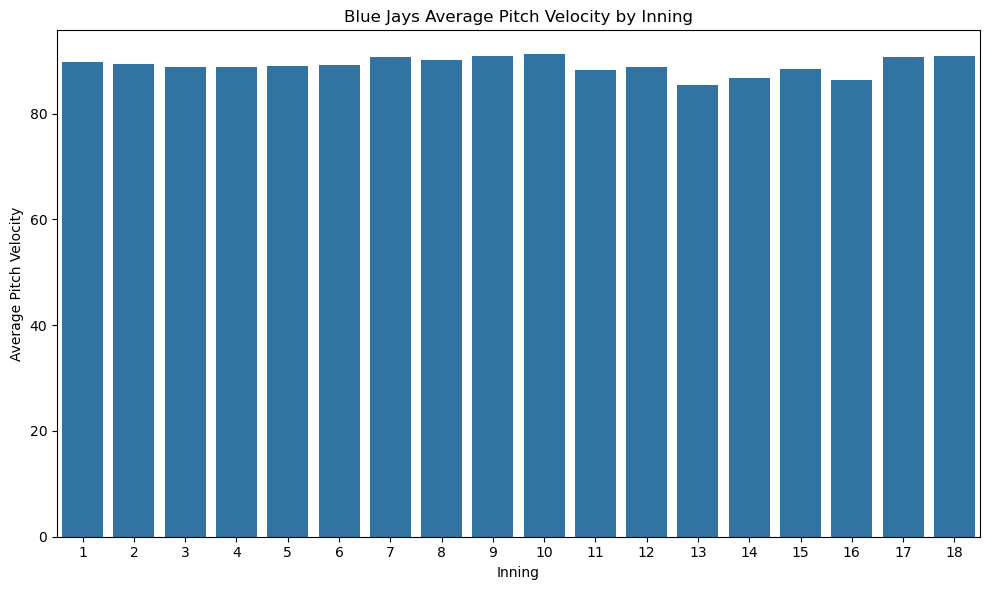

    inning  strikeout_rate
0        1        6.312292
1        2        9.642857
2        3        6.270627
3        4        6.976744
4        5        7.142857
5        6        5.466238
6        7        4.848485
7        8        6.040268
8        9        7.857143
9       10        2.173913
10      11        3.571429
11      12        8.333333
12      13        0.000000
13      14        0.000000
14      15        0.000000
15      16       18.181818
16      17        4.347826
17      18        0.000000


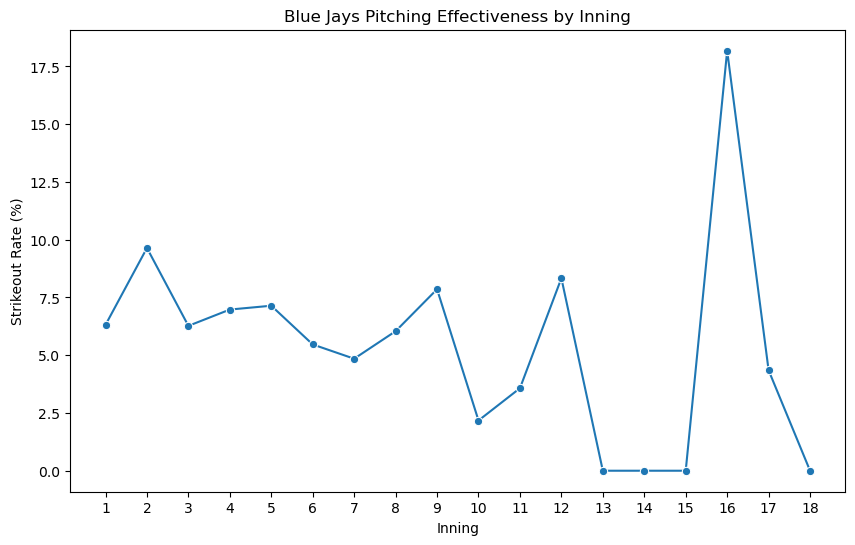

In [3]:
# Calculate average pitch velocity for each inning
velocity_by_inning = (
    blue_jays.groupby("inning")["release_speed"]
    .mean()
    .reset_index()
)

# Create the bar graph
plt.figure(figsize=(10, 6))

sns.barplot(
    data=velocity_by_inning,
    x="inning",
    y="release_speed"
)

print(velocity_by_inning)

plt.xlabel("Inning")
plt.ylabel("Average Pitch Velocity")
plt.title("Blue Jays Average Pitch Velocity by Inning")

plt.tight_layout()
plt.show()

effectiveness_by_inning = (
    blue_jays.groupby("inning")["events"]
    .apply(lambda x: (x == "strikeout").mean() * 100)
    .reset_index(name="strikeout_rate")
)

print(effectiveness_by_inning)

plt.figure(figsize=(10, 6))

sns.lineplot(
    data=effectiveness_by_inning,
    x="inning",
    y="strikeout_rate",
    marker="o"
)

plt.xlabel("Inning")
plt.ylabel("Strikeout Rate (%)")
plt.title("Blue Jays Pitching Effectiveness by Inning")
plt.xticks(sorted(effectiveness_by_inning["inning"].unique()))
plt.show()  

    inning  strike_zone_percentage
0        1               49.501661
1        2               46.785714
2        3               42.244224
3        4               50.000000
4        5               53.968254
5        6               48.231511
6        7               45.151515
7        8               48.657718
8        9               43.214286
9       10               47.826087
10      11               50.000000
11      12               50.000000
12      13               25.000000
13      14               48.148148
14      15               78.571429
15      16               63.636364
16      17               30.434783
17      18               50.000000
Most common pitch: FF
Number of pitches: 937


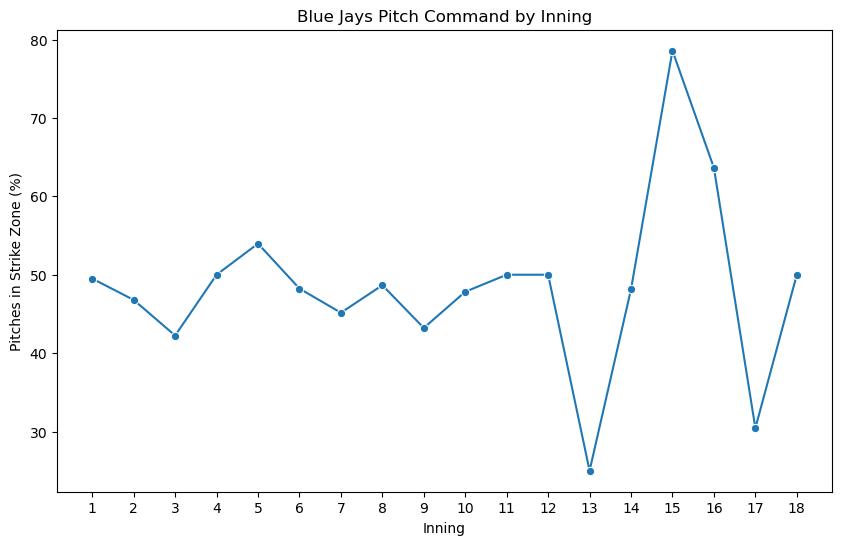

In [4]:
# Keep pitches that have a zone value
command_by_inning = (
    blue_jays.dropna(subset=["zone"])
    .groupby("inning")["zone"]
    .apply(lambda x: x.between(1, 9).mean() * 100)
    .reset_index(name="strike_zone_percentage")
)

print(command_by_inning)

pitch_counts = blue_jays["pitch_type"].value_counts()

print("Most common pitch:", pitch_counts.index[0])
print("Number of pitches:", pitch_counts.iloc[0])

plt.figure(figsize=(10, 6))

sns.lineplot(
    data=command_by_inning,
    x="inning",
    y="strike_zone_percentage",
    marker="o"
)

plt.xlabel("Inning")
plt.ylabel("Pitches in Strike Zone (%)")
plt.title("Blue Jays Pitch Command by Inning")
plt.xticks(sorted(command_by_inning["inning"].unique()))
plt.show()

In [5]:
print("Number of Blue Jays pitchers:",
      blue_jays["pitcher"].nunique())

print("\nPitchers:")
print(
    blue_jays[["pitcher", "player_name"]]
    .drop_duplicates()
    .sort_values("player_name")
    .to_string(index=False)
)

Number of Blue Jays pitchers: 15

Pitchers:
 pitcher           player_name
  605135        Bassitt, Chris
  669456         Bieber, Shane
  677865        Bruihl, Justin
  622554 Domínguez, Seranthony
  680755       Fisher, Braydon
  689254       Fluharty, Mason
  592332        Gausman, Kevin
  656546         Hoffman, Jeff
  641778           Lauer, Eric
  663893       Little, Brendon
  667297          Nance, Tommy
  684320     Rodríguez, Yariel
  453286         Scherzer, Max
  686973        Varland, Louis
  702056        Yesavage, Trey


In [6]:
print(blue_jays["pitch_type"].value_counts())

pitch_type
FF    937
SL    540
FS    402
FC    196
KC    174
SI    145
CU    136
ST    131
CH    127
Name: count, dtype: int64


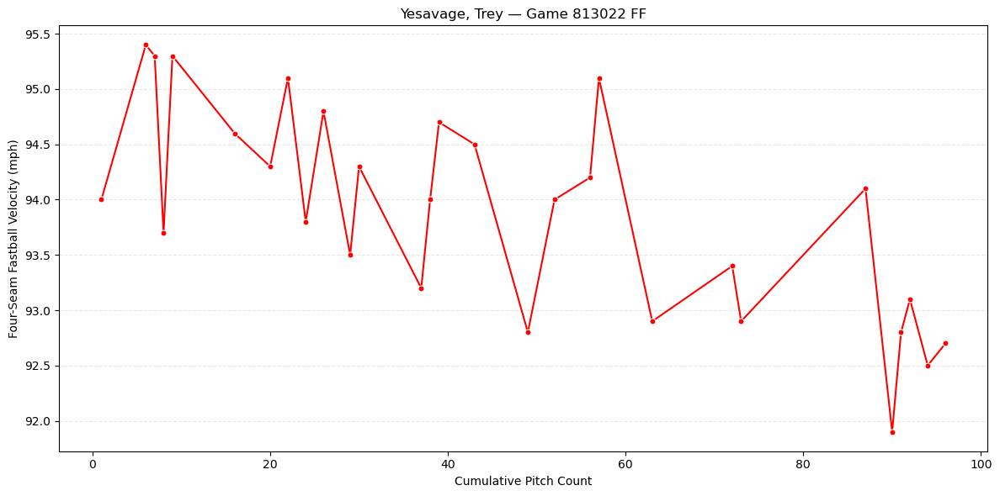

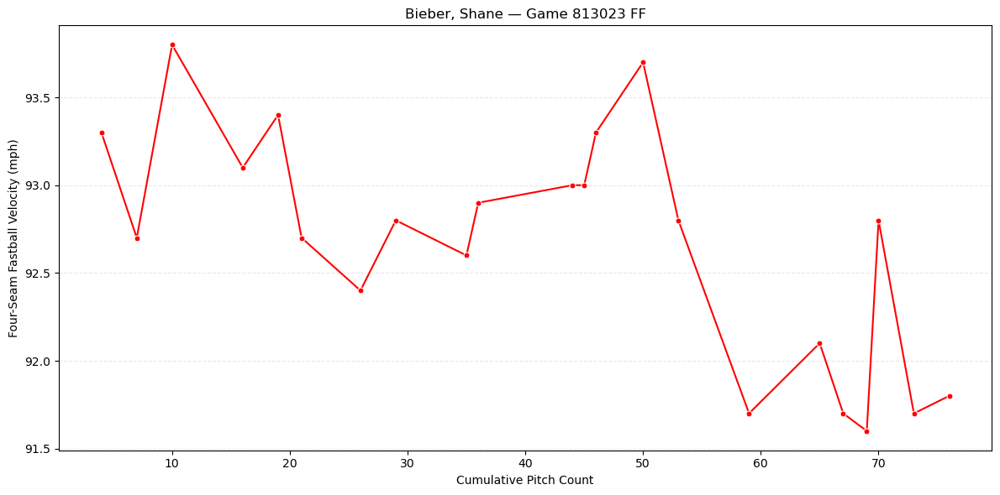

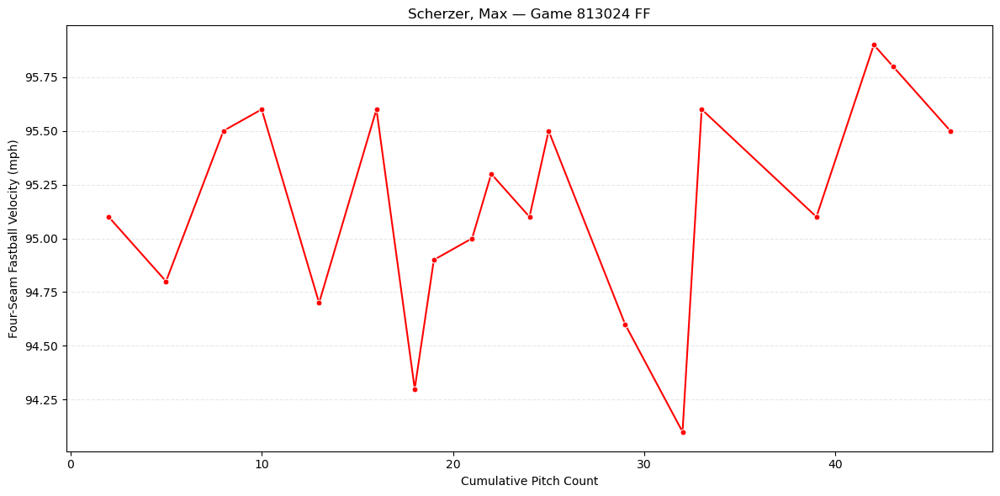

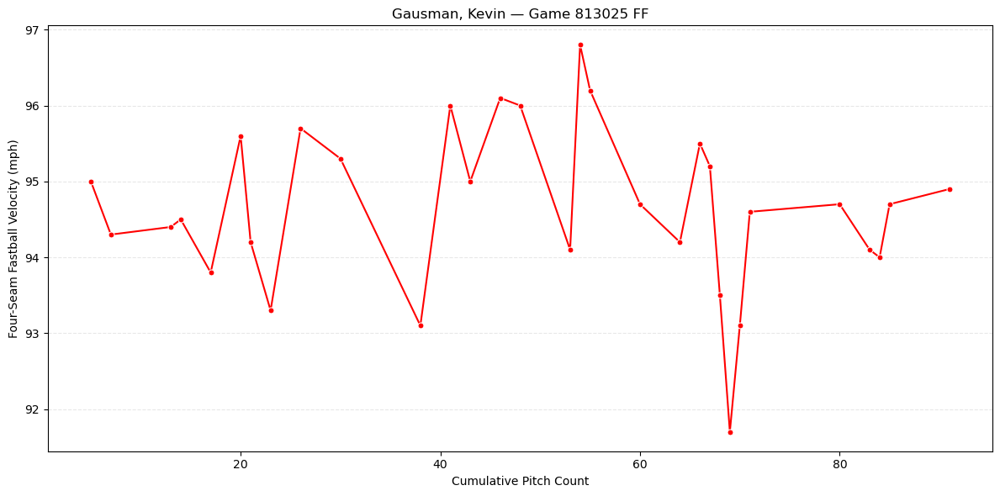

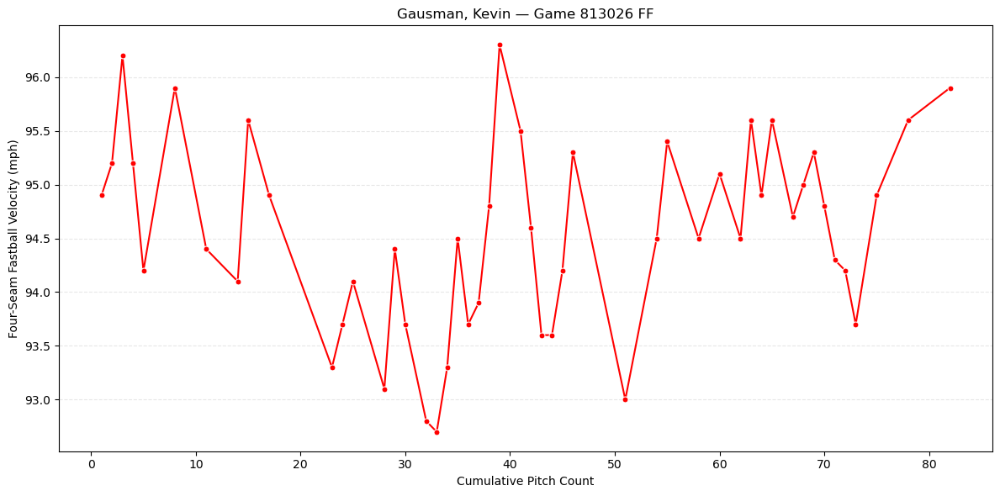

...

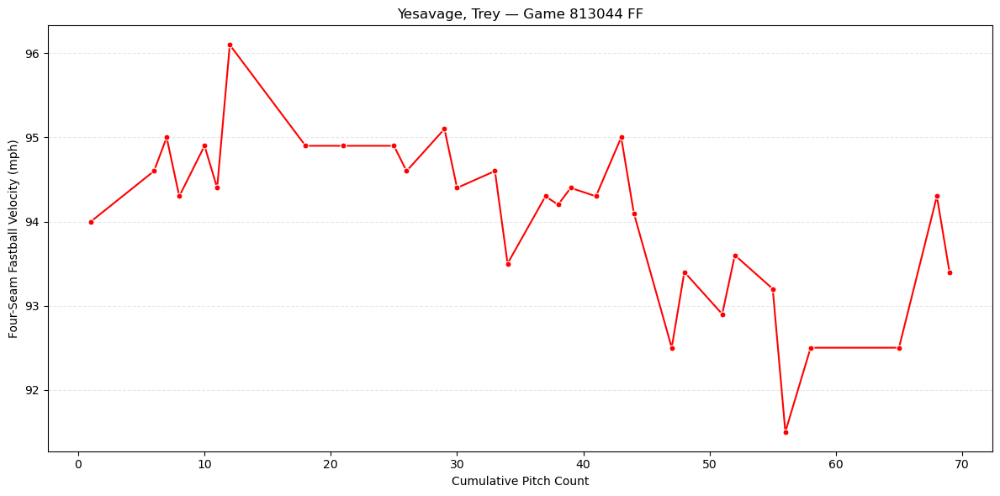

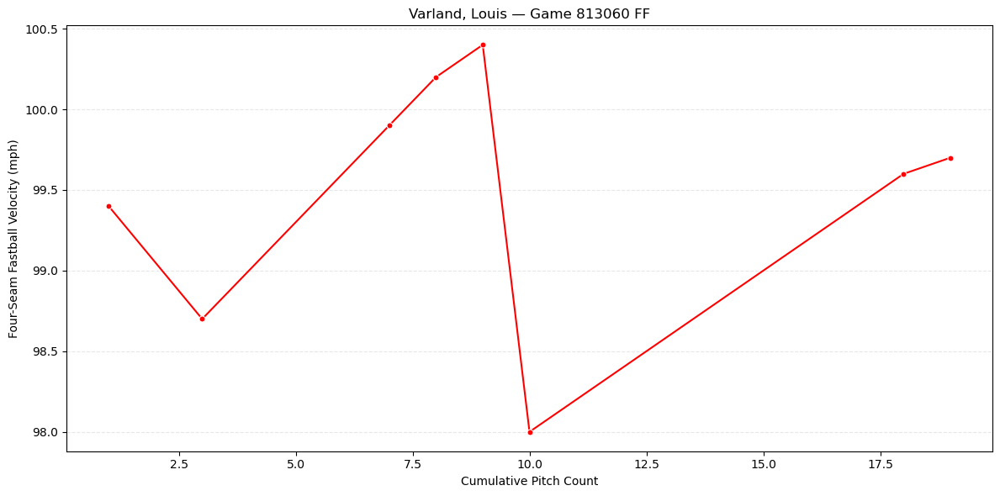

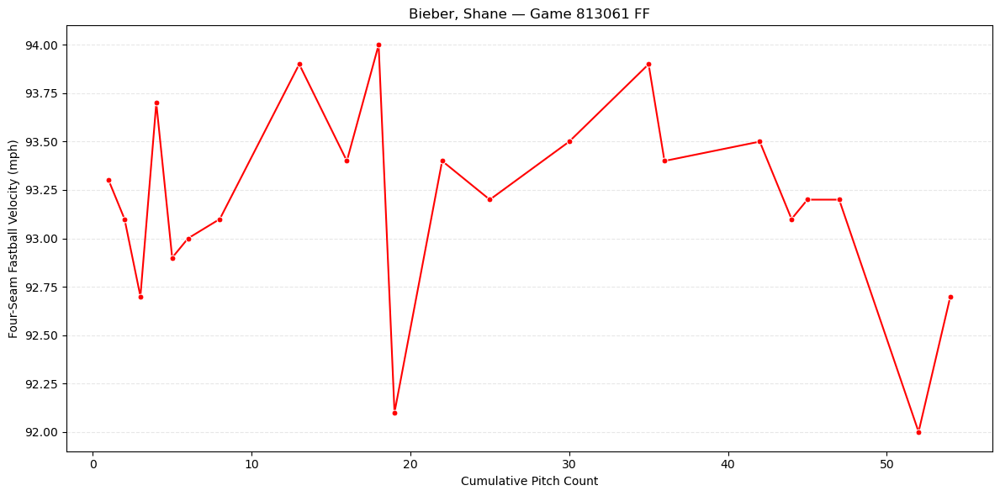

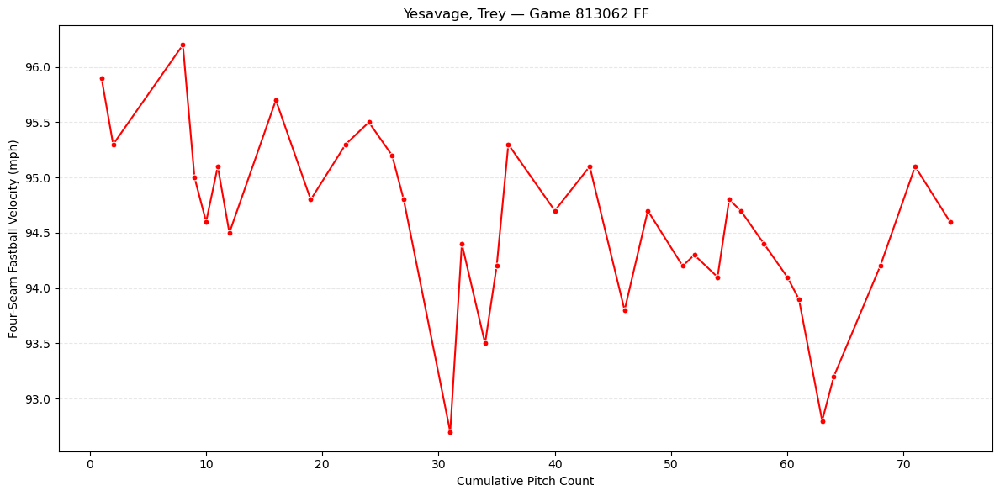

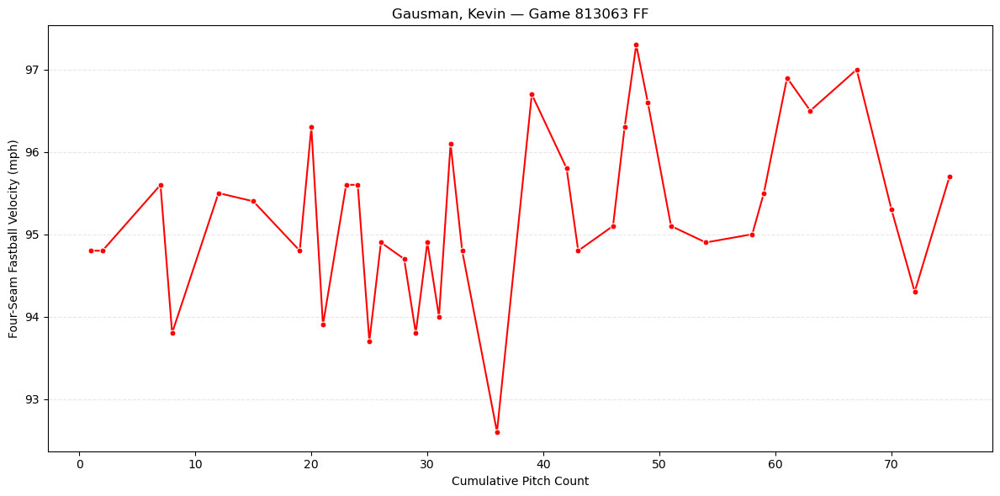

In [7]:
#velocity
# Keep pitches from innings 1 through 9
first_nine = blue_jays[
    blue_jays["inning"].between(1, 9)
].copy()

# Keep only four-seam fastballs
first_nine = first_nine[
    first_nine["pitch_type"] == "FF"
].copy()

# Sort pitches chronologically
first_nine = first_nine.sort_values(
    ["game_pk", "pitcher", "at_bat_number", "pitch_number"]
)

# Count all pitches in each pitcher's outing
all_pitches = blue_jays[
    blue_jays["inning"].between(1, 9)
].sort_values(
    ["game_pk", "pitcher", "at_bat_number", "pitch_number"]
).copy()

all_pitches["pitch_count"] = (
    all_pitches.groupby(["game_pk", "pitcher"]).cumcount() + 1
)


# Keep pitches from innings 1 through 9
first_nine = blue_jays[
    blue_jays["inning"].between(1, 9)
].copy()

# Sort pitches chronologically
first_nine = first_nine.sort_values(
    ["game_pk", "at_bat_number", "pitch_number"]
)

# Identify the first Toronto pitcher in each game
starters = (
    first_nine.groupby("game_pk")
    .first()
    .reset_index()[["game_pk", "pitcher", "player_name"]]
)

# Get all pitches for each starting pitcher in their game
starter_pitches = first_nine.merge(
    starters[["game_pk", "pitcher"]],
    on=["game_pk", "pitcher"],
    how="inner"
)

# Count every pitch, not just fastballs
starter_pitches["pitch_count"] = (
    starter_pitches.groupby(["game_pk", "pitcher"]).cumcount() + 1
)

# Keep only four-seam fastballs
starter_ff = starter_pitches[
    starter_pitches["pitch_type"] == "FF"
].copy()

# One graph for each starting pitcher in their game
for i in range(len(starters)):
    starter = starters.iloc[i]

    pitcher_data = starter_ff[
        (starter_ff["game_pk"] == starter["game_pk"]) &
        (starter_ff["pitcher"] == starter["pitcher"])
    ].sort_values("pitch_count")

    if pitcher_data.empty:
        continue

    plt.figure(figsize=(12, 6))
    
    sns.lineplot(
        data=pitcher_data,
        x="pitch_count",
        y="release_speed",
        color="red",
        marker="o",
        markersize=5,
        linewidth=1.5
    )

    plt.xlabel("Cumulative Pitch Count")
    plt.ylabel("Four-Seam Fastball Velocity (mph)")
    plt.title(
        f"{starter['player_name']} — Game {starter['game_pk']} FF"
    )
    plt.grid(axis="y", linestyle="--", alpha=0.3)
    plt.tight_layout()
    plt.show()

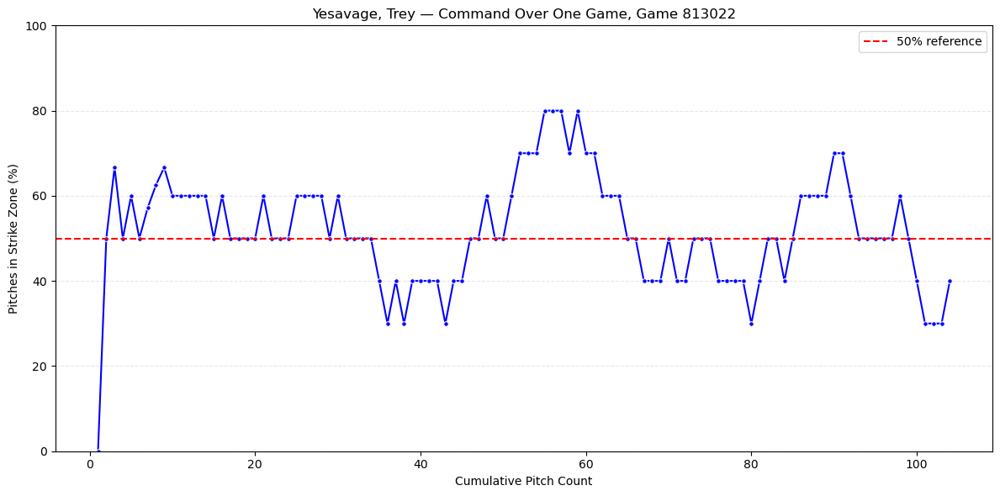

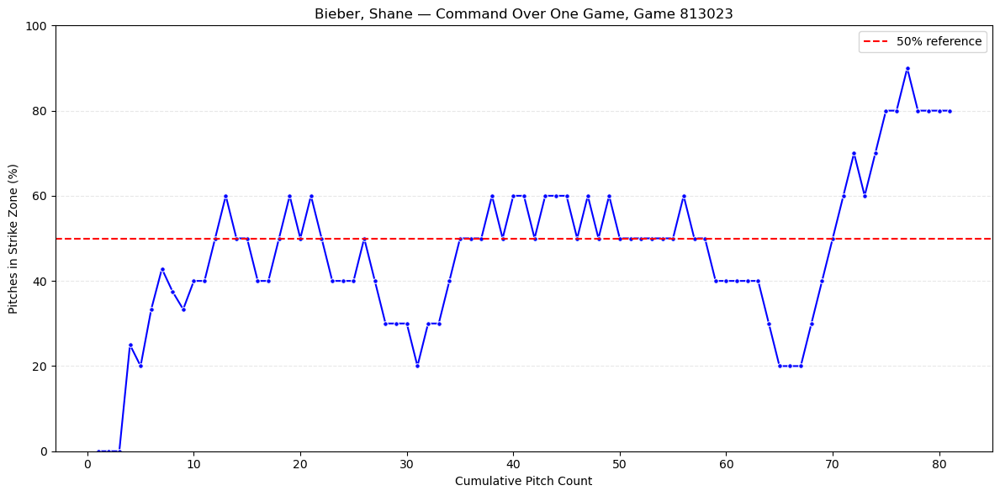

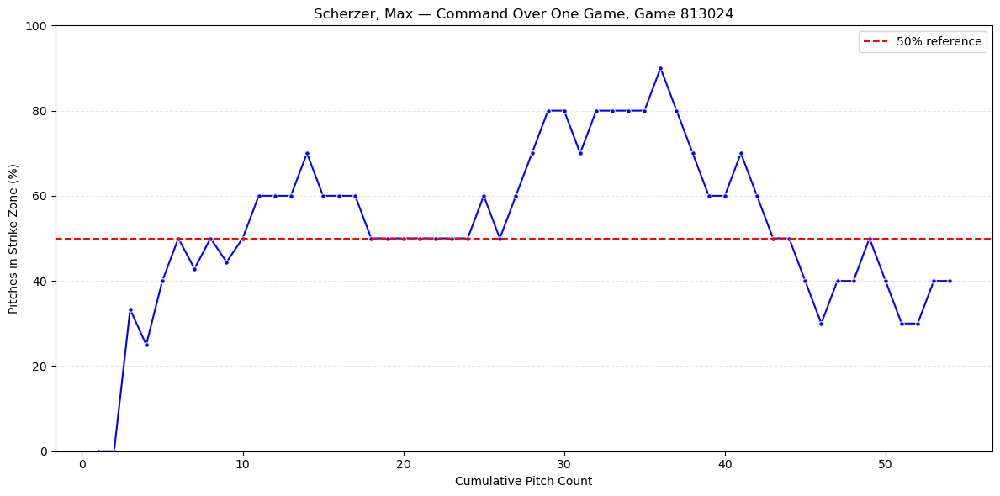

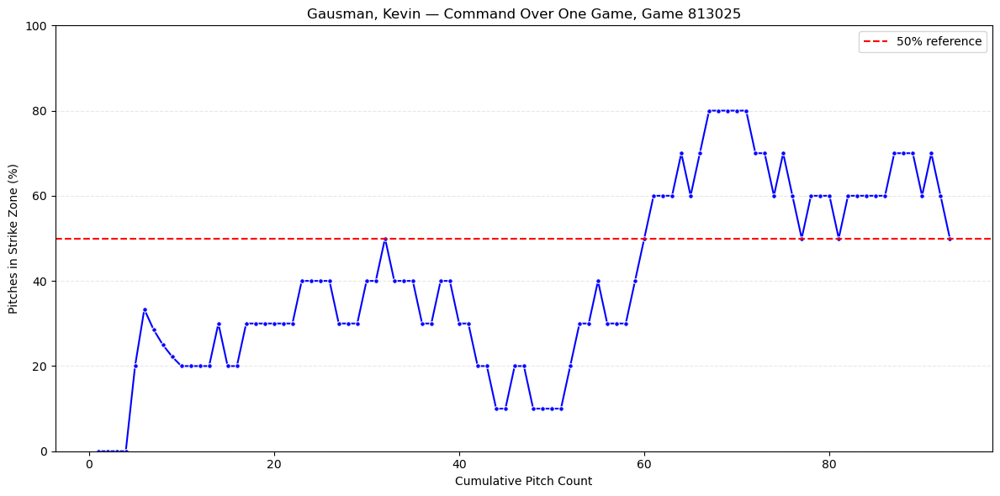

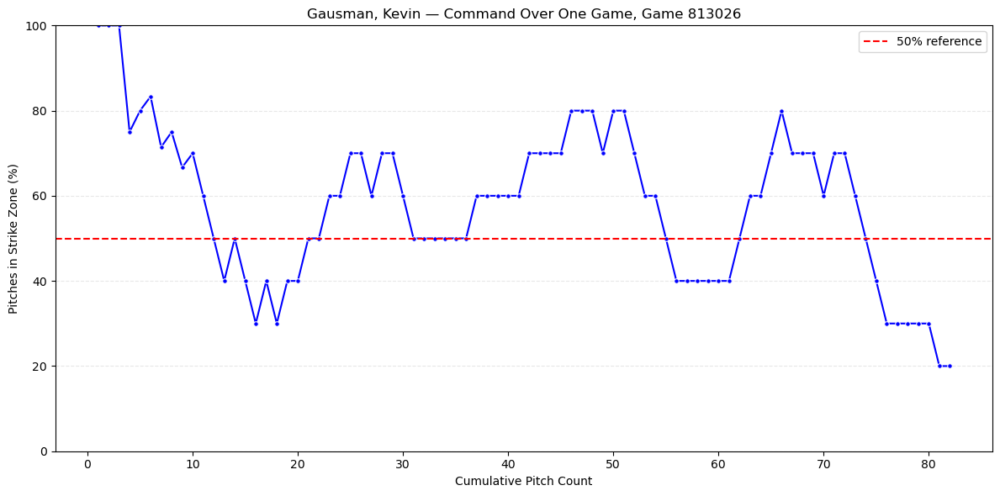

...

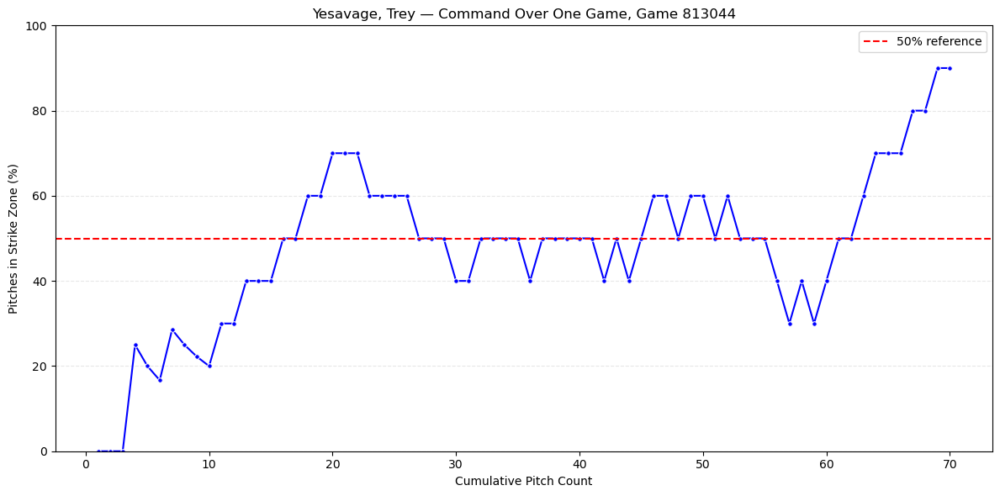

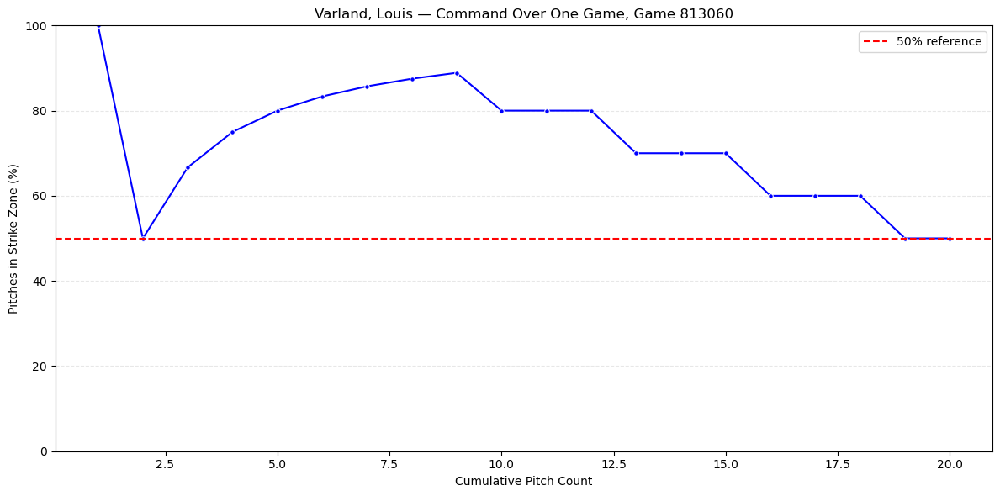

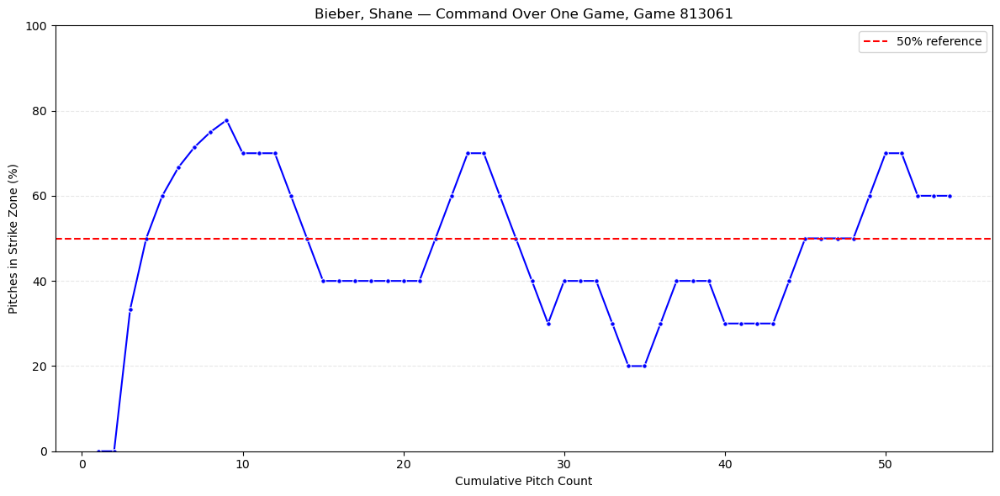

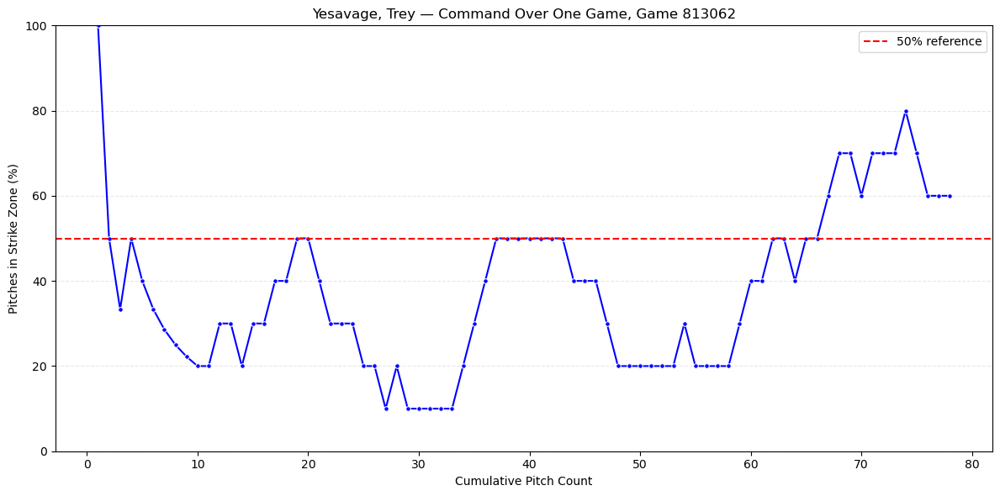

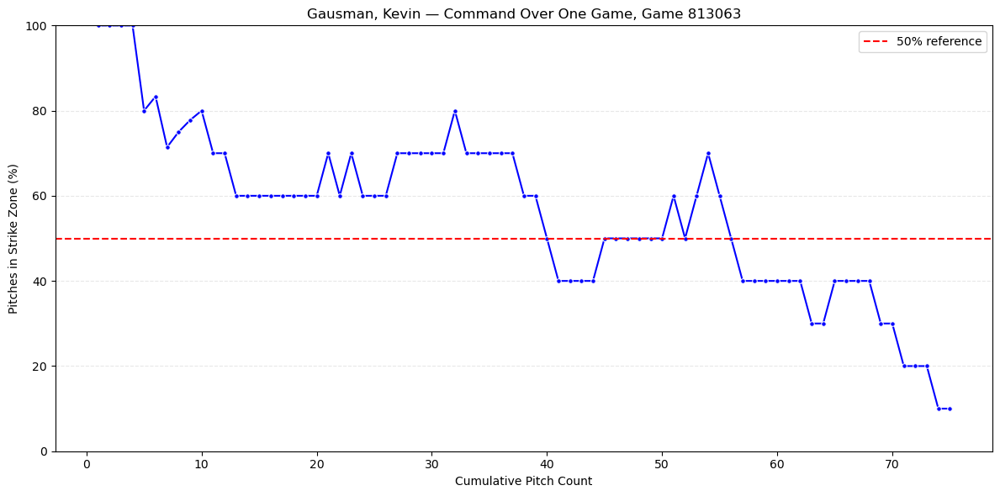

In [8]:
# #command
# Keep pitches from innings 1 through 9
first_nine = blue_jays[
    blue_jays["inning"].between(1, 9)
].copy()

# Sort pitches chronologically
first_nine = first_nine.sort_values(
    ["game_pk", "at_bat_number", "pitch_number"]
)

# Identify the first Toronto pitcher in each game
starters = (
    first_nine.groupby("game_pk")
    .first()
    .reset_index()[["game_pk", "pitcher", "player_name"]]
)

# Get each starting pitcher's pitches in their game
starter_pitches = first_nine.merge(
    starters[["game_pk", "pitcher"]],
    on=["game_pk", "pitcher"],
    how="inner"
)

# Count all pitches in each outing
starter_pitches["pitch_count"] = (
    starter_pitches.groupby(["game_pk", "pitcher"]).cumcount() + 1
)

# Mark whether each pitch was in the strike zone
starter_pitches["in_zone"] = (
    starter_pitches["zone"].between(1, 9)
)

# Calculate rolling command percentage over the last 10 pitches
for i in range(len(starters)):

    # Get the current starting pitcher's information using the row index
    starter = starters.iloc[i]

    pitcher_data = starter_pitches[
        (starter_pitches["game_pk"] == starter["game_pk"]) &
        (starter_pitches["pitcher"] == starter["pitcher"])
    ].copy()

    if pitcher_data.empty:
        continue

    pitcher_data = pitcher_data.sort_values("pitch_count")

    pitcher_data["command_percentage"] = (
        pitcher_data["in_zone"]
        .rolling(window=10, min_periods=1)
        .mean() * 100
    )

    plt.figure(figsize=(12, 6))

    sns.lineplot(
        data=pitcher_data,
        x="pitch_count",
        y="command_percentage",
        color="blue",
        marker="o",
        markersize=4
    )

    plt.axhline(
        50,
        color="red",
        linestyle="--",
        label="50% reference"
    )

    plt.xlabel("Cumulative Pitch Count")
    plt.ylabel("Pitches in Strike Zone (%)")
    plt.title(
        f"{starter['player_name']} — Command Over One Game, Game {starter['game_pk']}"
    )

    plt.ylim(0, 100)
    plt.grid(axis="y", linestyle="--", alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()

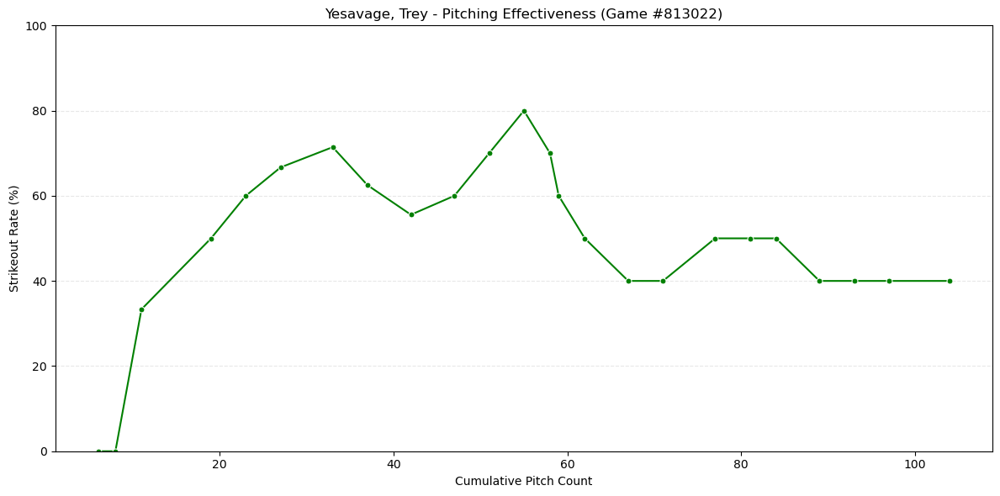

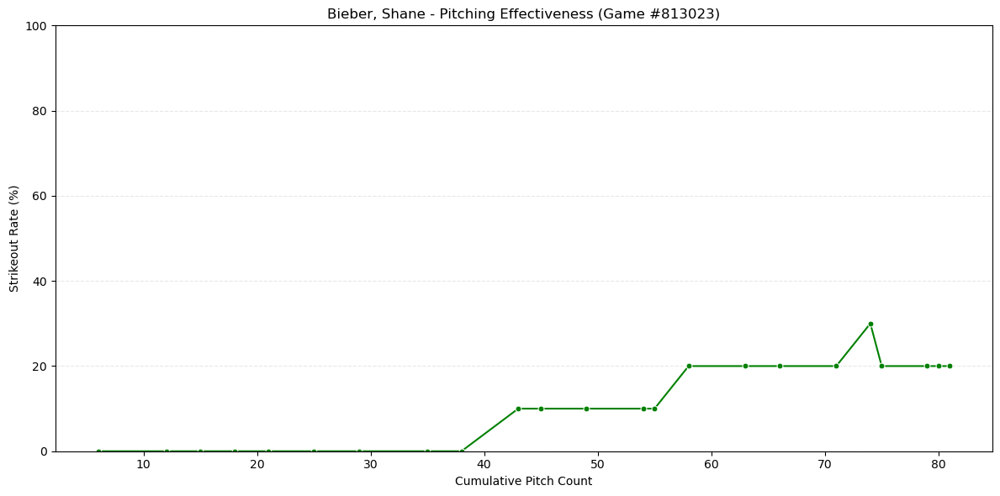

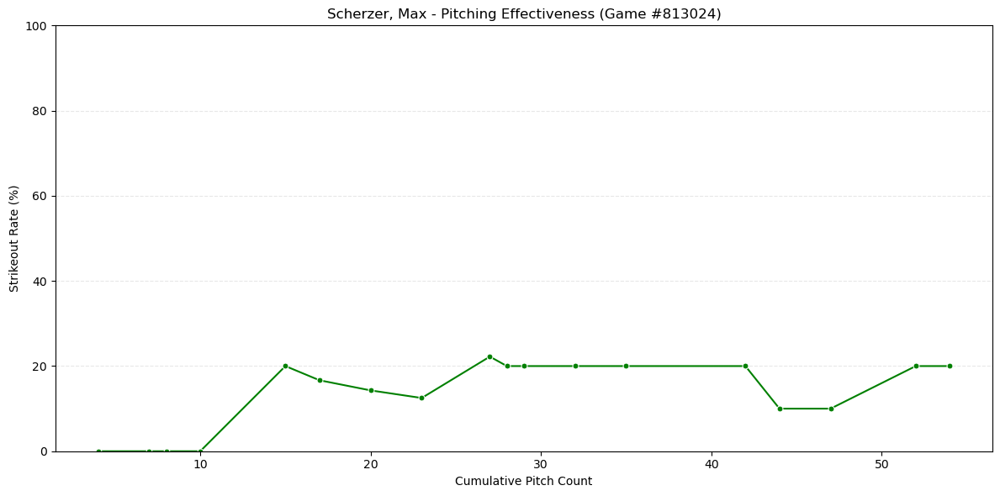

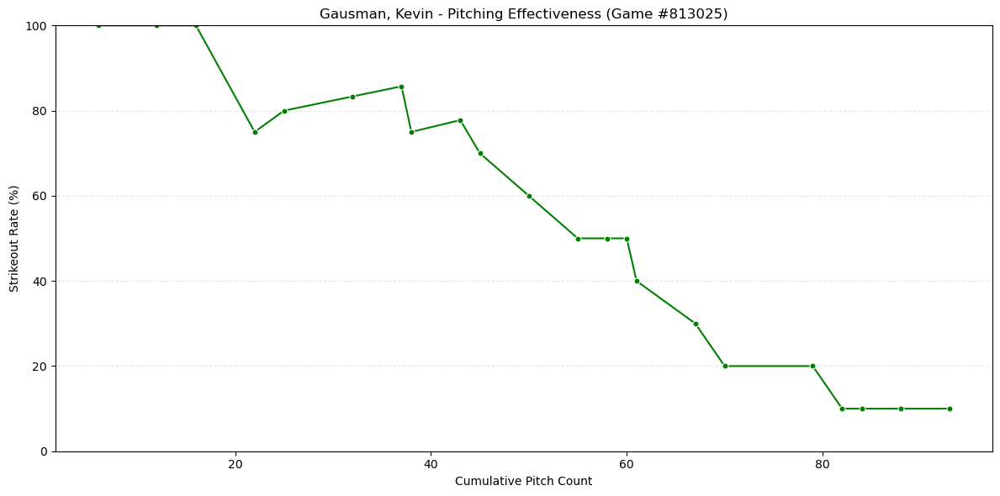

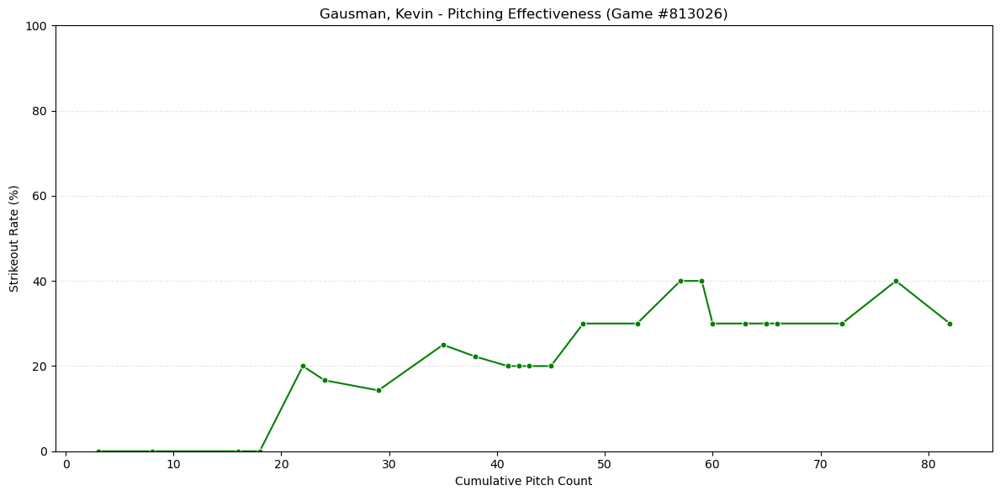

...

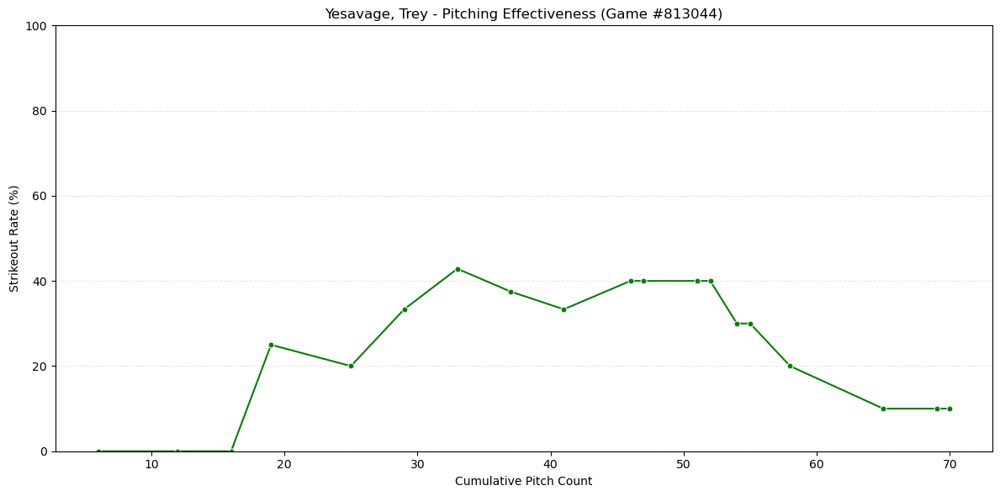

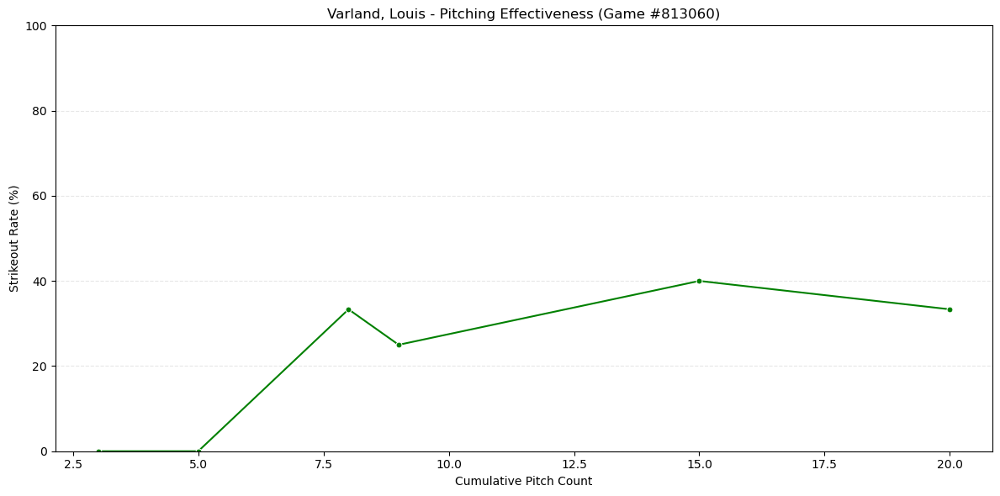

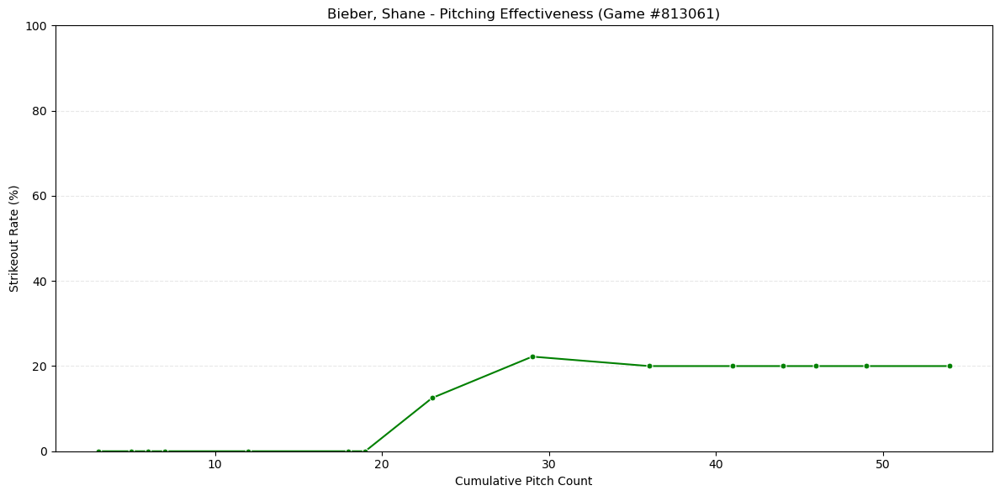

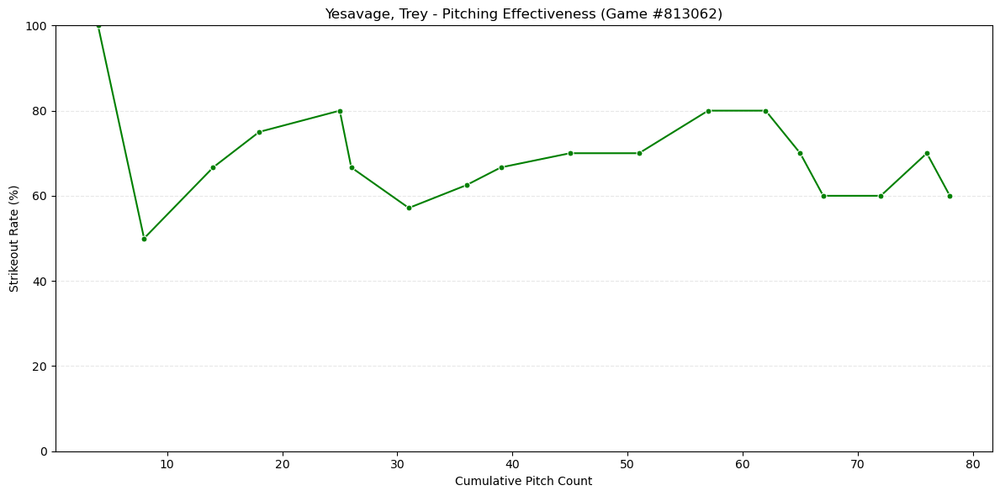

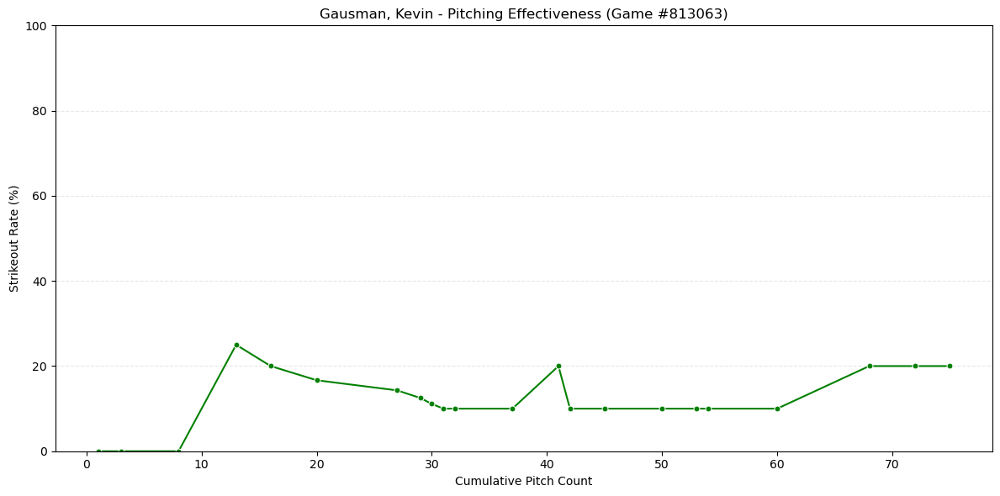

In [9]:
#effectiveness
#Keep pitches from innings 1 through 9
first_nine = blue_jays[
    blue_jays["inning"].between(1, 9)
].copy()

# Sort pitches chronologically
first_nine = first_nine.sort_values(
    ["game_pk", "at_bat_number", "pitch_number"]
)

# Identify the first Toronto pitcher in each game
starters = (
    first_nine.groupby("game_pk")
    .first()
    .reset_index()[["game_pk", "pitcher", "player_name"]]
)

# Get each starter's pitches in their game
starter_pitches = first_nine.merge(
    starters[["game_pk", "pitcher"]],
    on=["game_pk", "pitcher"],
    how="inner"
)

# Count all pitches during each outing
starter_pitches["pitch_count"] = (
    starter_pitches.groupby(["game_pk", "pitcher"]).cumcount() + 1
)

# Identify completed plate appearances
# Events is normally populated on the final pitch of an at-bat
starter_pitches["completed_pa"] = (
    starter_pitches["events"].notna()
)

# Mark strikeouts on completed plate appearances
starter_pitches["strikeout"] = (
    starter_pitches["events"] == "strikeout"
)

# Create a graph for each starting pitcher and game
for i in range(len(starters)):

    # Get the current starting pitcher's information using the row index
    starter = starters.iloc[i]

    # Select pitches thrown by this pitcher in this specific game
    pitcher_data = starter_pitches[
        (starter_pitches["game_pk"] == starter["game_pk"]) &
        (starter_pitches["pitcher"] == starter["pitcher"])
    ].copy()

    # Sort the pitcher's data by cumulative pitch count
    pitcher_data = pitcher_data.sort_values("pitch_count")

    # Keep only completed plate appearances to calculate strikeout rate
    pa_data = pitcher_data[pitcher_data["completed_pa"]].copy()

    # Skip this pitcher if there are no completed plate appearances
    if pa_data.empty:
        continue

    # Calculate the rolling strikeout rate over the last 10 completed
    # plate appearances, using all available appearances if fewer than 10
    pa_data["strikeout_rate"] = (
        pa_data["strikeout"]
        .rolling(window=10, min_periods=1)
        .mean() * 100
    )

    # Create a new figure for the current pitcher
    plt.figure(figsize=(12, 6))

    # Draw a green line showing how strikeout rate changes with pitch count
    sns.lineplot(
        data=pa_data,
        x="pitch_count",
        y="strikeout_rate",
        color="green",
        marker="o",
        markersize=5
    )

    # Label the x-axis with the cumulative number of pitches thrown
    plt.xlabel("Cumulative Pitch Count")

    # Label the y-axis with the rolling strikeout rate as a percentage
    plt.ylabel("Strikeout Rate (%)")

    # Add the pitcher's name and game number as the graph title
    plt.title(
        f"{starter['player_name']} - Pitching Effectiveness "
        f"(Game #{starter['game_pk']})"
    )

    # Set the y-axis range from 0% to 100%
    plt.ylim(0, 100)

    # Add horizontal dashed gridlines to make the graph easier to read
    plt.grid(axis="y", linestyle="--", alpha=0.3)

    # Adjust the layout to prevent labels and titles from overlapping
    plt.tight_layout()

    # Display the graph for the current pitcher
    plt.show()

In [10]:
# calculate player stats

# Keep Blue Jays pitches from innings 1–9
pitch_data = blue_jays[
    blue_jays["inning"].between(1, 9)
].copy()

# Identify pitches inside the strike zone
pitch_data["zone"] = pd.to_numeric(
    pitch_data["zone"], errors="coerce"
)
pitch_data["in_zone"] = pitch_data["zone"].between(1, 9)

# Identify completed plate appearances and strikeouts
pitch_data["completed_pa"] = pitch_data["events"].notna()

pitch_data["strikeout"] = pitch_data["events"].isin([
    "strikeout", "strikeout_double_play"
])

# Calculate individual pitcher statistics
pitcher_stats = (
    pitch_data.groupby(["pitcher", "player_name"])
    .agg(
        games=("game_pk", "nunique"),
        avg_velocity=("release_speed", "mean"),
        pitches_thrown=("pitch_number", "size"),
        zone_pitches=("in_zone", "sum"),
        completed_pa=("completed_pa", "sum"),
        strikeouts=("strikeout", "sum")
    )
    .reset_index()
)

# Calculate strike-zone percentage for command
pitcher_stats["strike_zone_percentage"] = (
    pitcher_stats["zone_pitches"]
    / pitcher_stats["pitches_thrown"] * 100
)

# Calculate strikeout rate as a measure of effectiveness
pitcher_stats["strikeout_rate_percentage"] = (
    pitcher_stats["strikeouts"]
    / pitcher_stats["completed_pa"].replace(0, np.nan) * 100
)

# Sort pitchers by the number of pitches thrown
pitcher_stats = pitcher_stats.sort_values(
    "pitches_thrown", ascending=False
)

# Print statistics for at least five individual pitchers
print(pitcher_stats[[
            "player_name",
            "games",
            "avg_velocity",
            "strike_zone_percentage",
            "strikeout_rate_percentage"
        ]
    ].to_string(index=False)
)

          player_name  games  avg_velocity  strike_zone_percentage  strikeout_rate_percentage
       Yesavage, Trey      6     89.150682               46.136364                  36.111111
       Gausman, Kevin      6     89.287615               47.247706                  22.413793
        Bieber, Shane      4     87.951178               47.811448                  22.784810
       Varland, Louis     15     93.938800               49.600000                  26.153846
        Scherzer, Max      3     89.028636               48.181818                  18.965517
        Hoffman, Jeff     10     90.875000               44.680851                  41.463415
Domínguez, Seranthony     11     93.343605               43.604651                  22.727273
      Fluharty, Mason     11     86.644203               46.376812                  30.000000
       Bassitt, Chris      7     87.186066               54.098361                  33.333333
      Fisher, Braydon      7     88.292857               49.

          player_name  games  average_velocity
       Varland, Louis     15             98.50
Domínguez, Seranthony     11             96.98
        Hoffman, Jeff      9             95.88
      Little, Brendon      2             95.85
      Fisher, Braydon      6             95.80
    Rodríguez, Yariel      3             95.53
       Gausman, Kevin      6             94.97
        Scherzer, Max      3             94.90
       Yesavage, Trey      6             94.47
        Bieber, Shane      4             93.05
       Bassitt, Chris      6             92.73
          Lauer, Eric      4             91.65


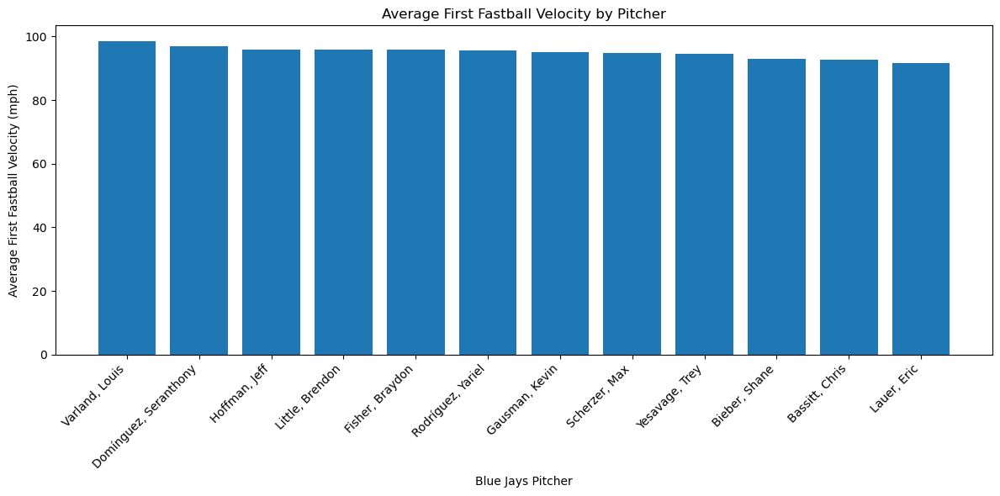

In [11]:
# Keep only the first 9 innings and four-seam fastballs
fastballs = blue_jays[
    (blue_jays["inning"].between(1, 9)) &
    (blue_jays["pitch_type"] == "FF")
].copy()

# Sort pitches in the order they were thrown
fastballs = fastballs.sort_values(
    ["game_pk", "at_bat_number", "pitch_number"]
)

# Get each player's first fastball in each game
first_fastballs = fastballs.groupby(
    ["game_pk", "pitcher", "player_name"]
).first().reset_index()

player_averages = (
    first_fastballs.groupby(["pitcher", "player_name"])
    .agg(
        games=("game_pk", "nunique"),
        average_velocity=("release_speed", "mean")
    )
    .reset_index()
    .sort_values("average_velocity", ascending=False)
)

print(
    player_averages[
        ["player_name", "games", "average_velocity"]
    ].round(2).to_string(index=False)
)

plt.figure(figsize=(12, 6))

plt.bar(
    player_averages["player_name"],
    player_averages["average_velocity"]
)

plt.xlabel("Blue Jays Pitcher")
plt.ylabel("Average First Fastball Velocity (mph)")
plt.title("Average First Fastball Velocity by Pitcher")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

          player_name  games  in_zone_pct
        Hoffman, Jeff      9        77.78
          Lauer, Eric      4        75.00
Domínguez, Seranthony     11        72.73
        Scherzer, Max      3        66.67
       Varland, Louis     15        66.67
       Gausman, Kevin      6        66.67
       Bassitt, Chris      6        50.00
      Little, Brendon      2        50.00
       Yesavage, Trey      6        33.33
    Rodríguez, Yariel      3        33.33
        Bieber, Shane      4        25.00
      Fisher, Braydon      6        16.67


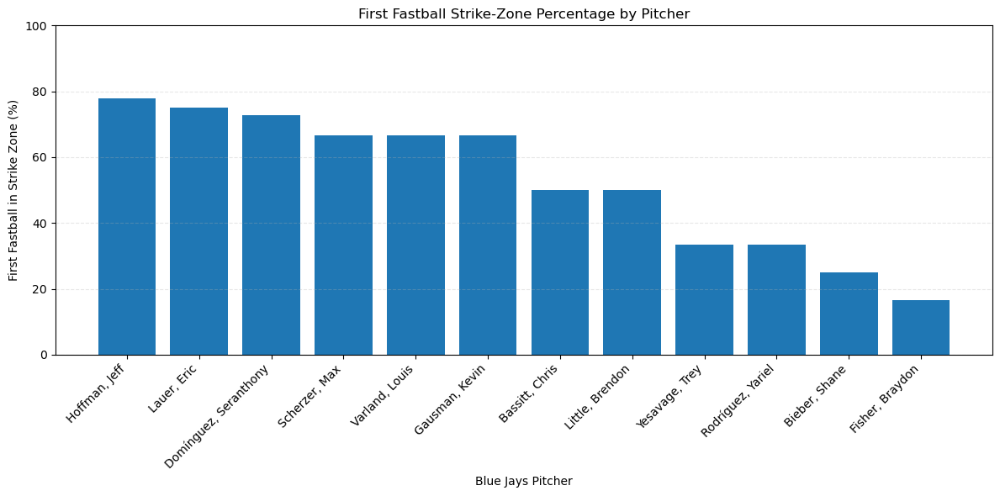

In [12]:
#command for first
# Keep four-seam fastballs from the first 9 innings
fastballs = blue_jays[
    (blue_jays["inning"].between(1, 9)) &
    (blue_jays["pitch_type"] == "FF")
].copy()

# Sort pitches chronologically within each game
fastballs = fastballs.sort_values(
    ["game_pk", "at_bat_number", "pitch_number"]
)

# Get each player's first fastball in each game
first_fastballs = fastballs.groupby(
    ["game_pk", "pitcher", "player_name"]
).first().reset_index()

# Identify whether the pitch was in the strike zone
first_fastballs["in_zone"] = first_fastballs["zone"].between(1, 9)

command_stats = (
    first_fastballs.groupby(["pitcher", "player_name"])
    .agg(
        games=("game_pk", "nunique"),
        first_fastballs_in_zone=("in_zone", "sum"),
        total_first_fastballs=("in_zone", "count")
    )
    .reset_index()
)

command_stats["in_zone_pct"] = (
    command_stats["first_fastballs_in_zone"] /
    command_stats["total_first_fastballs"] * 100
)

print(
    command_stats[
        ["player_name", "games", "in_zone_pct"]
    ].sort_values("in_zone_pct", ascending=False).round(2).to_string(index=False)
)

# Sort players from highest to lowest strike-zone percentage
command_stats = command_stats.sort_values(
    "in_zone_pct", ascending=False
)

# Create bar chart
plt.figure(figsize=(12, 6))

plt.bar(
    command_stats["player_name"],
    command_stats["in_zone_pct"]
)

plt.xlabel("Blue Jays Pitcher")
plt.ylabel("First Fastball in Strike Zone (%)")
plt.title("First Fastball Strike-Zone Percentage by Pitcher")
plt.ylim(0, 100)
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

          player_name  games  strikeouts  completed_pa  strikeout_rate_pct
        Hoffman, Jeff     10          17            41               41.46
       Yesavage, Trey      6          39           108               36.11
          Lauer, Eric      4           6            17               35.29
       Bassitt, Chris      7          10            30               33.33
      Fisher, Braydon      7           8            26               30.77
      Fluharty, Mason     11           9            30               30.00
       Varland, Louis     15          17            65               26.15
        Bieber, Shane      4          18            79               22.78
Domínguez, Seranthony     11          10            44               22.73
       Gausman, Kevin      6          26           116               22.41
        Scherzer, Max      3          11            58               18.97
      Little, Brendon      5           2            17               11.76
    Rodríguez, Yariel    

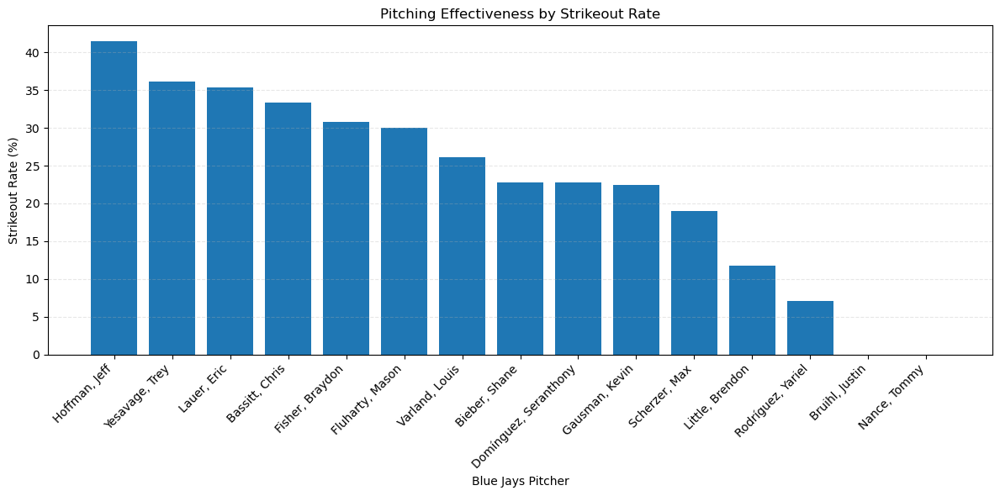

In [13]:
# Keep pitches from the first 9 innings
pitch_data = blue_jays[
    blue_jays["inning"].between(1, 9)
].copy()

# Identify completed plate appearances and strikeouts
pitch_data["completed_pa"] = pitch_data["events"].notna()

pitch_data["strikeout"] = pitch_data["events"].isin([
    "strikeout",
    "strikeout_double_play"
])

# Calculate statistics for each pitcher
effectiveness_stats = (
    pitch_data.groupby(["pitcher", "player_name"])
    .agg(
        games=("game_pk", "nunique"),
        strikeouts=("strikeout", "sum"),
        completed_pa=("completed_pa", "sum")
    )
    .reset_index()
)

# Calculate strikeout rate
effectiveness_stats["strikeout_rate_pct"] = (
    effectiveness_stats["strikeouts"] /
    effectiveness_stats["completed_pa"].replace(0, float("nan")) * 100
)

# Sort from highest to lowest strikeout rate
effectiveness_stats = effectiveness_stats.sort_values(
    "strikeout_rate_pct", ascending=False
)

print(
    effectiveness_stats[
        ["player_name", "games", "strikeouts",
         "completed_pa", "strikeout_rate_pct"]
    ].round(2).to_string(index=False)
)

plt.figure(figsize=(12, 6))

plt.bar(
    effectiveness_stats["player_name"],
    effectiveness_stats["strikeout_rate_pct"]
)

plt.xlabel("Blue Jays Pitcher")
plt.ylabel("Strikeout Rate (%)")
plt.title("Pitching Effectiveness by Strikeout Rate")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

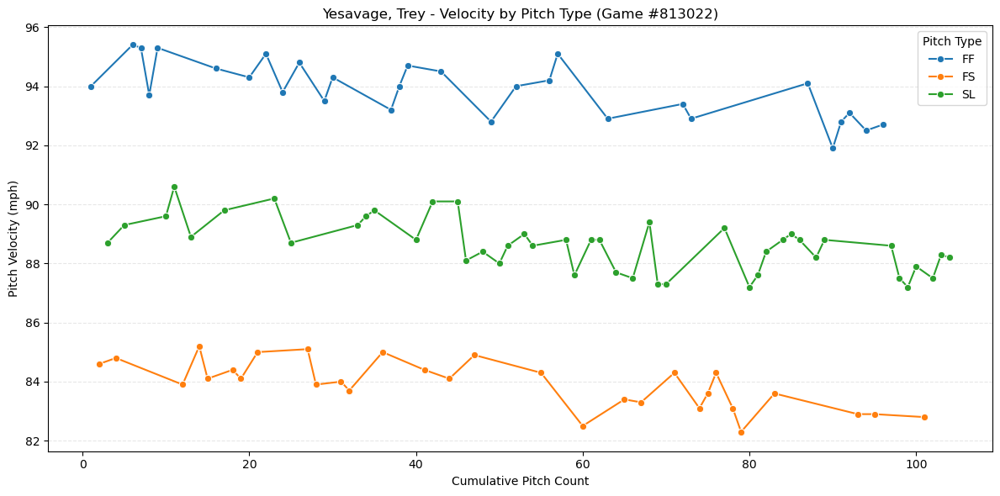

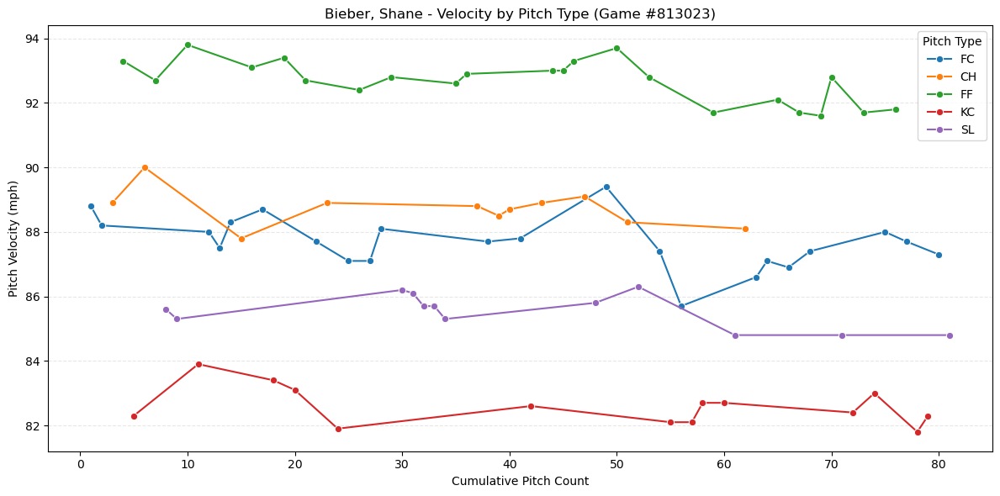

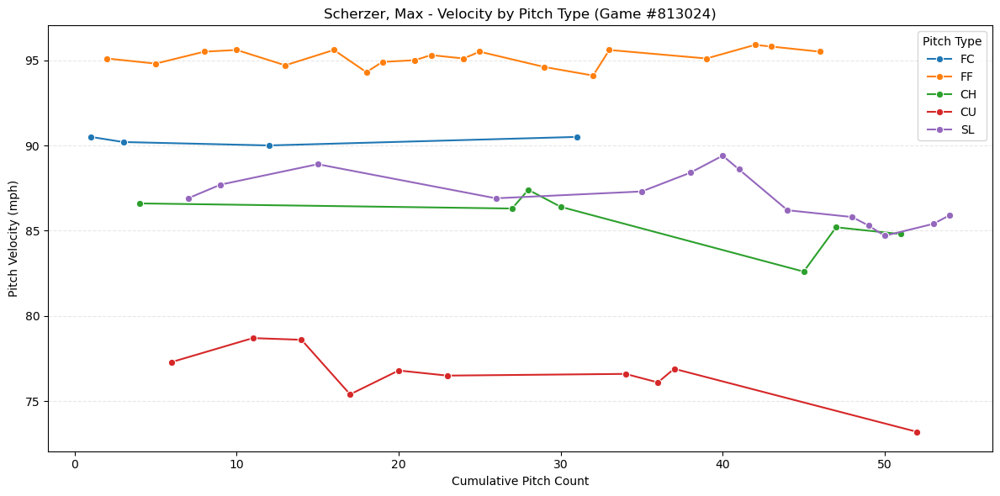

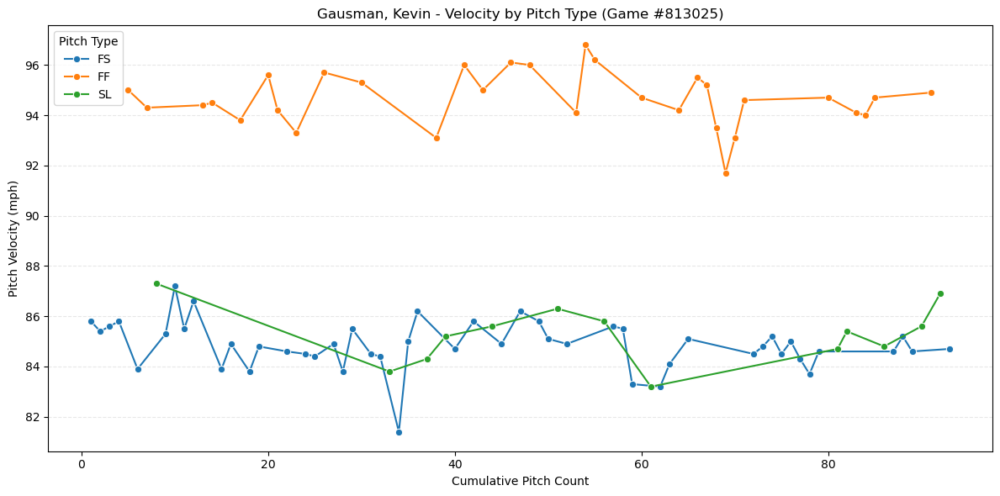

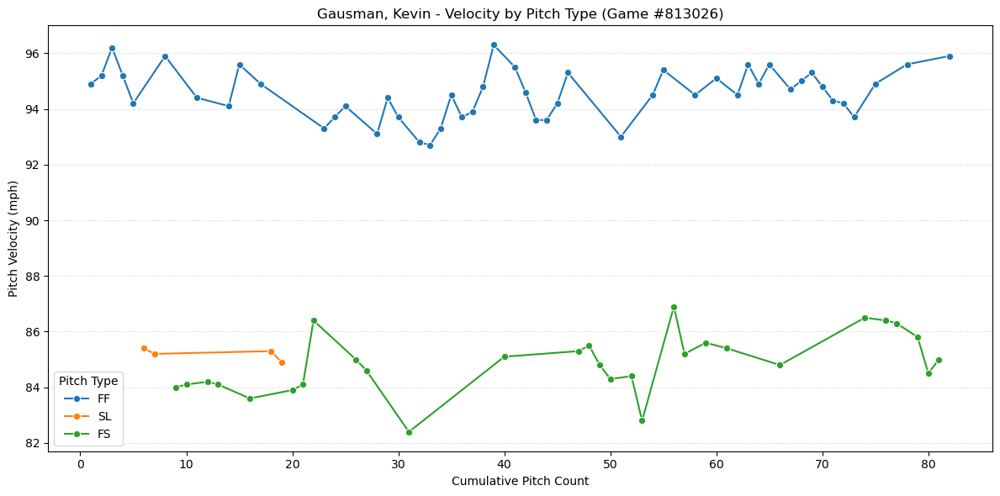

...

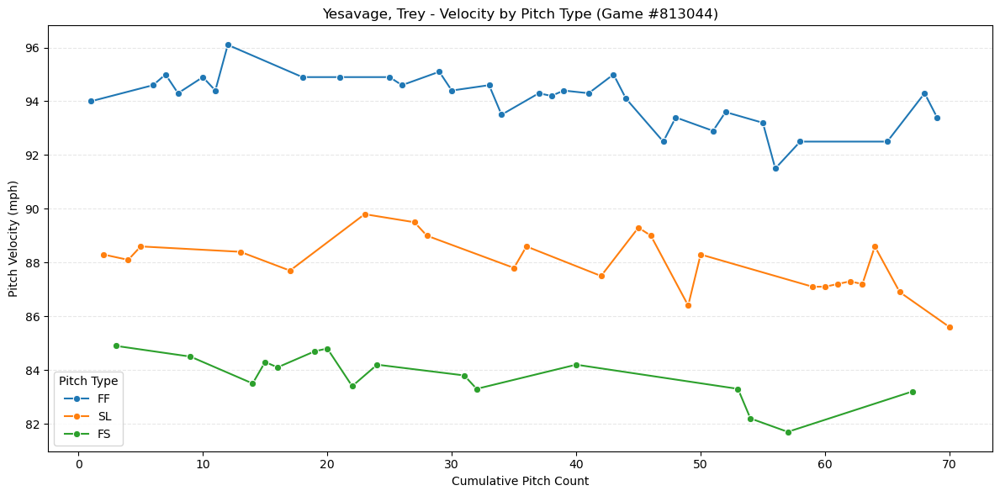

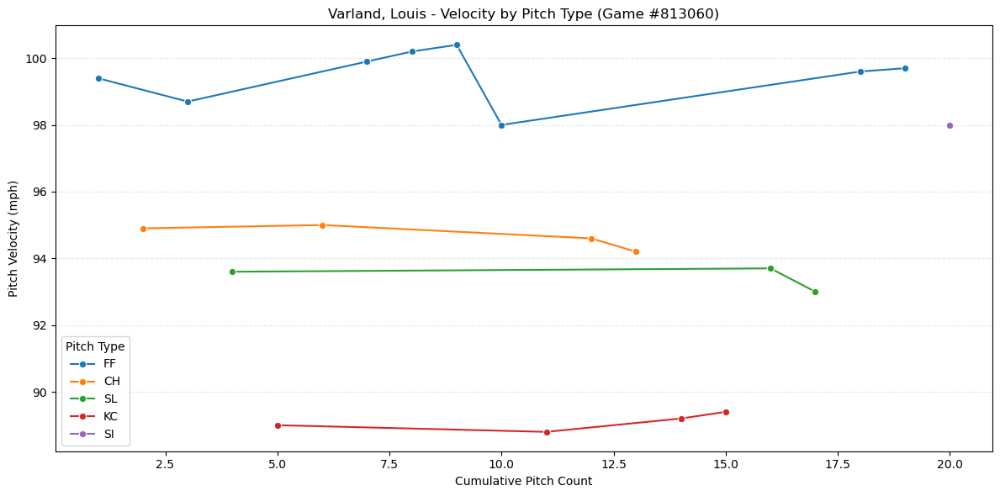

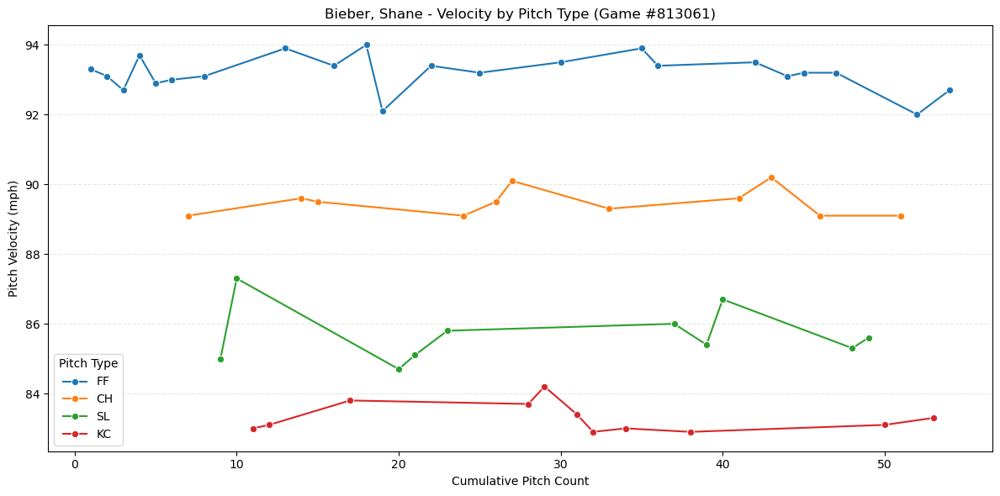

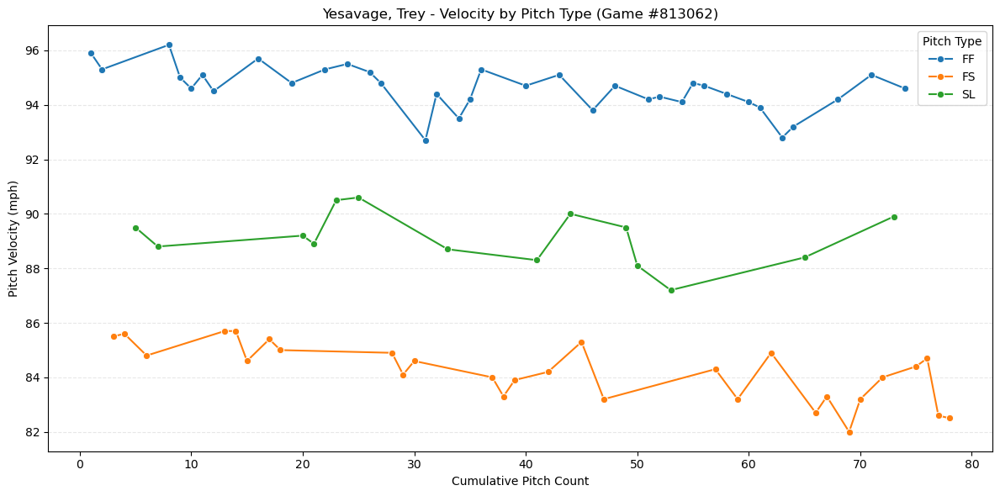

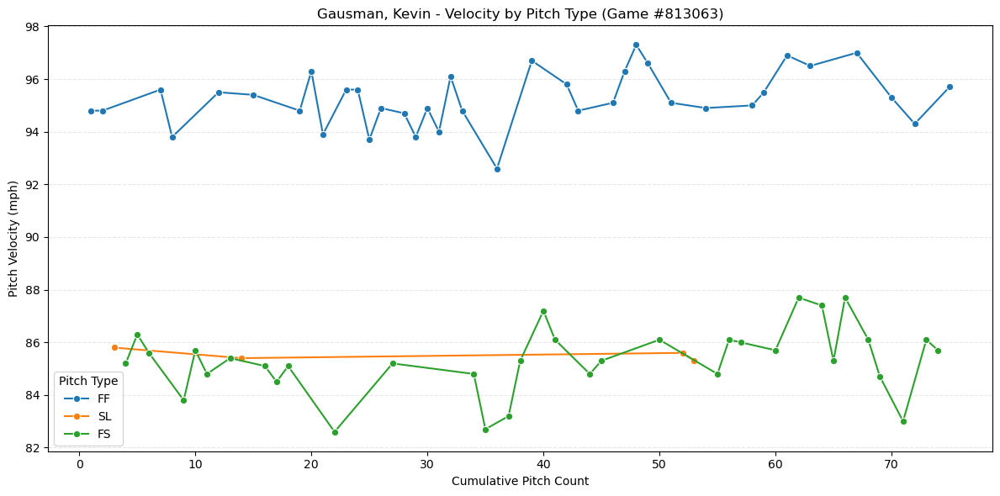

In [14]:
# Get only starting pitchers
starter_pitches = pitch_data.merge(
    starters[["game_pk", "pitcher"]],
    on=["game_pk", "pitcher"],
    how="inner"
)

# Sort pitches chronologically
starter_pitches = starter_pitches.sort_values(
    ["game_pk", "pitcher", "at_bat_number", "pitch_number"]
)

# Calculate cumulative pitch count
starter_pitches["pitch_count"] = (
    starter_pitches.groupby(["game_pk", "pitcher"]).cumcount() + 1
)

for i in range(len(starters)):

    starter = starters.iloc[i]

    pitcher_data = starter_pitches[
        (starter_pitches["game_pk"] == starter["game_pk"]) &
        (starter_pitches["pitcher"] == starter["pitcher"])
    ].copy()

    plt.figure(figsize=(12, 6))

    sns.lineplot(
        data=pitcher_data,
        x="pitch_count",
        y="release_speed",
        hue="pitch_type",
        marker="o"
    )

    plt.xlabel("Cumulative Pitch Count")
    plt.ylabel("Pitch Velocity (mph)")

    plt.title(
        f"{starter['player_name']} - Velocity by Pitch Type "
        f"(Game #{starter['game_pk']})"
    )

    plt.legend(title="Pitch Type")
    plt.grid(axis="y", linestyle="--", alpha=0.3)
    plt.tight_layout()
    plt.show()

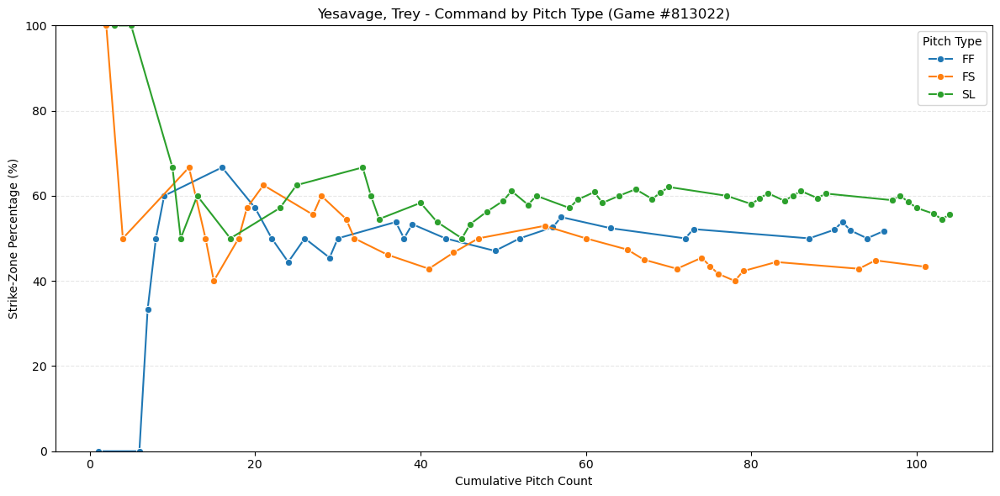

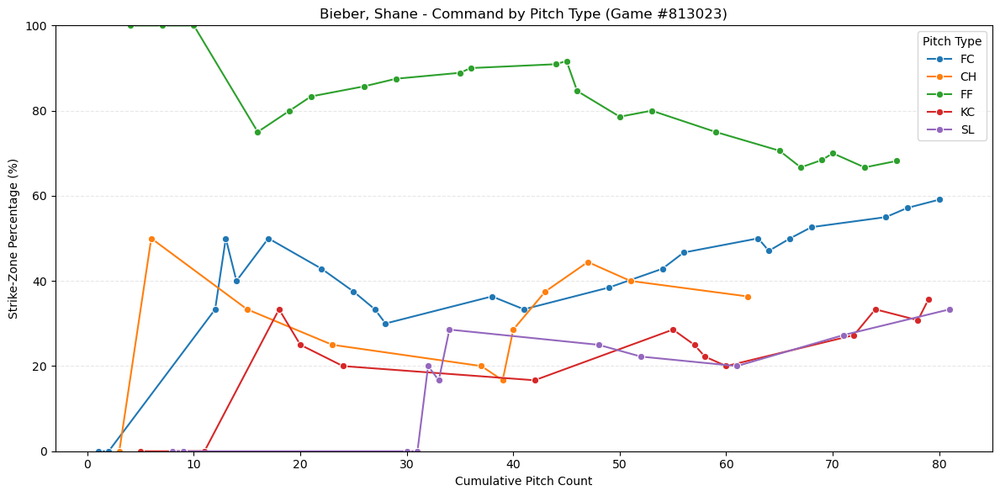

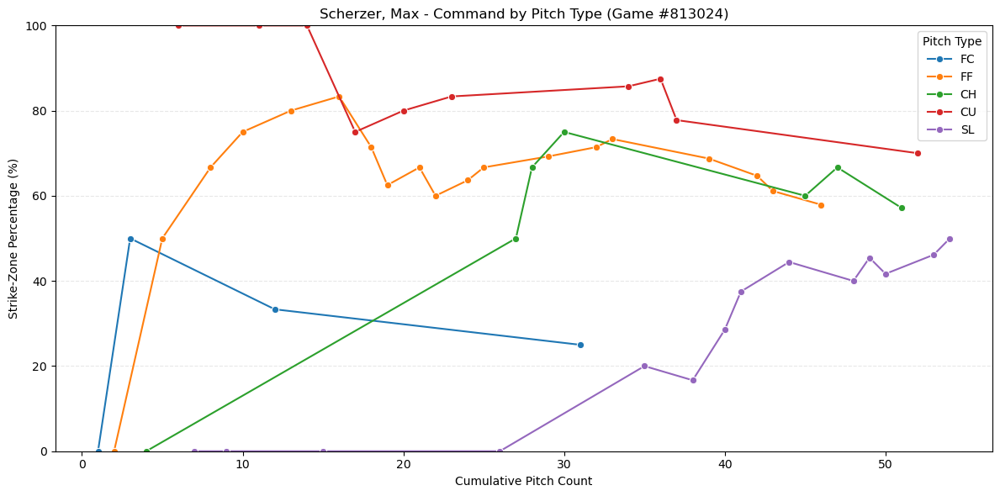

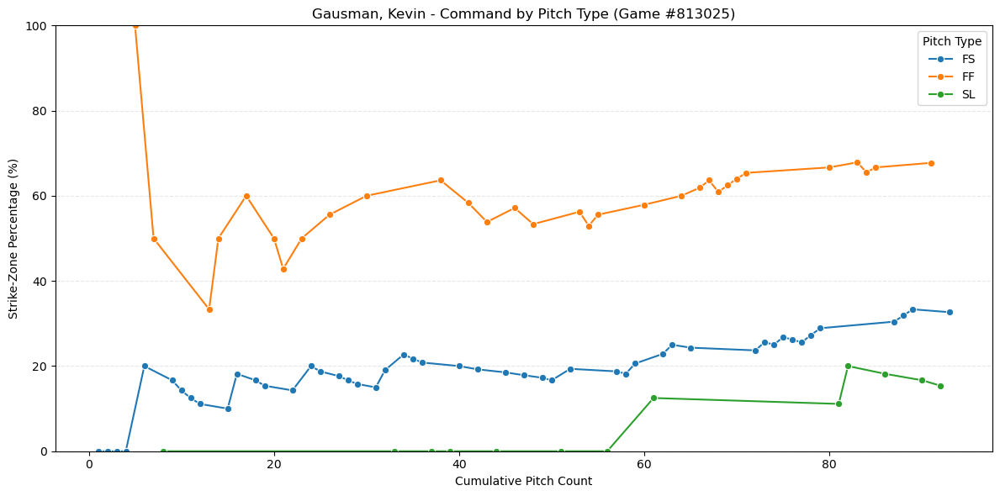

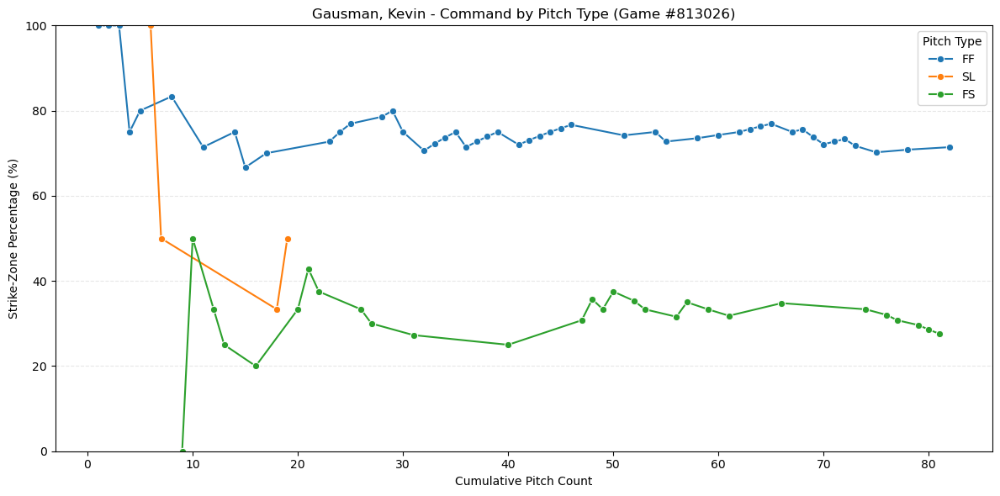

...

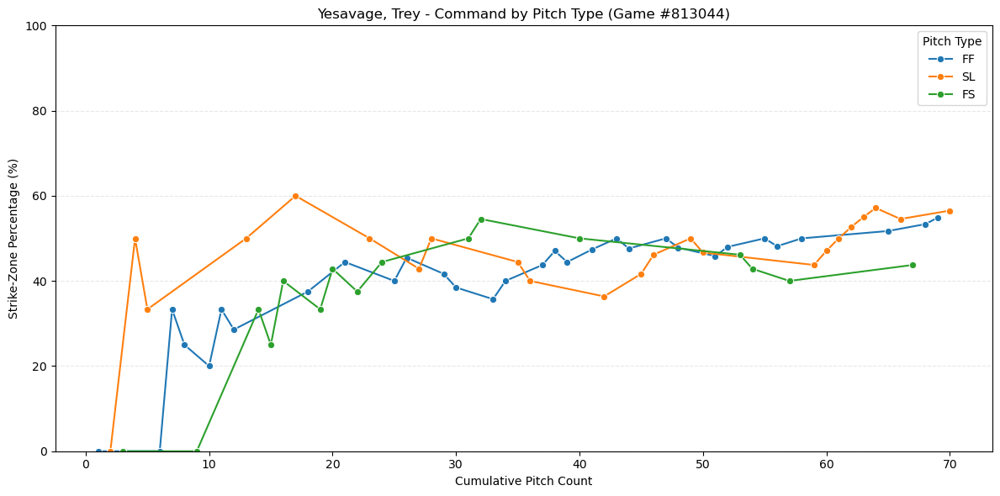

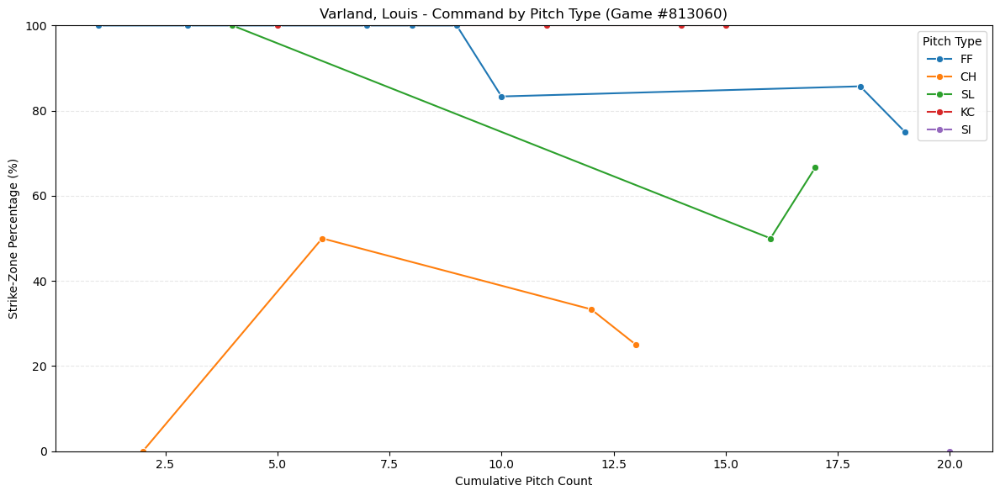

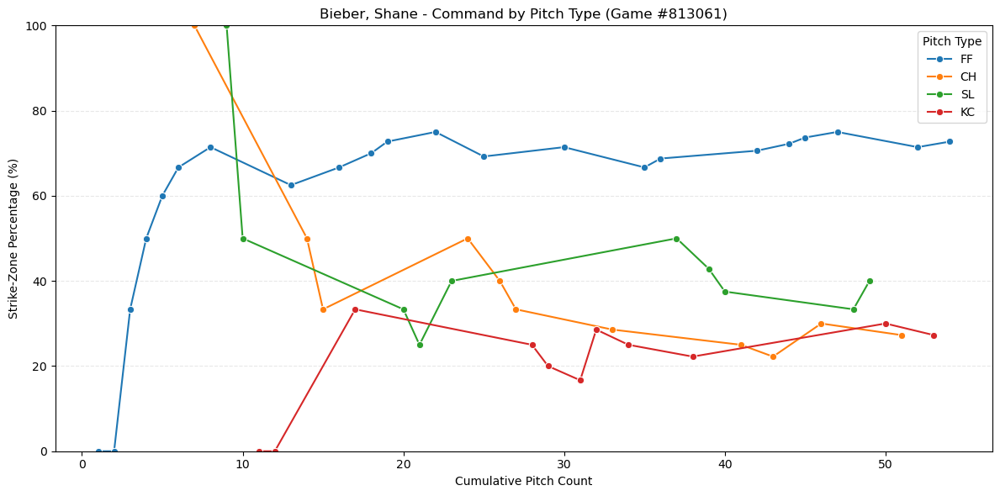

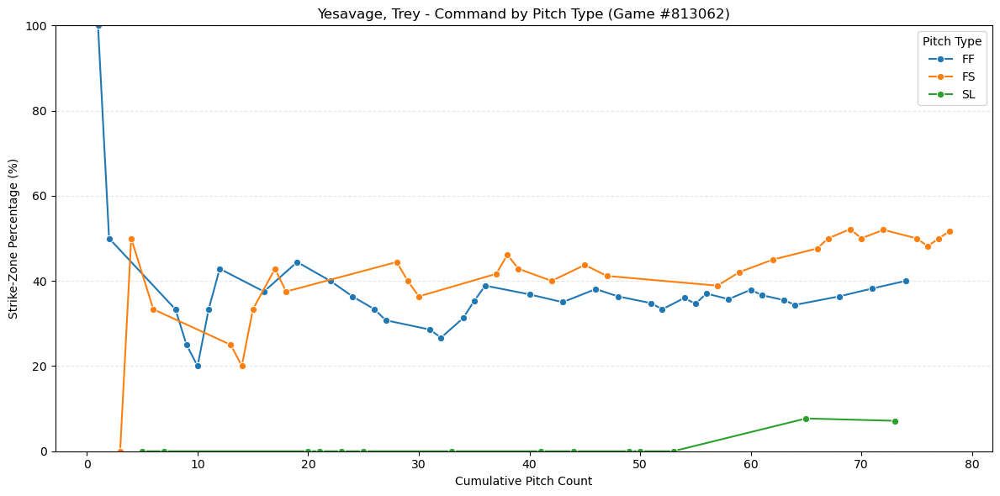

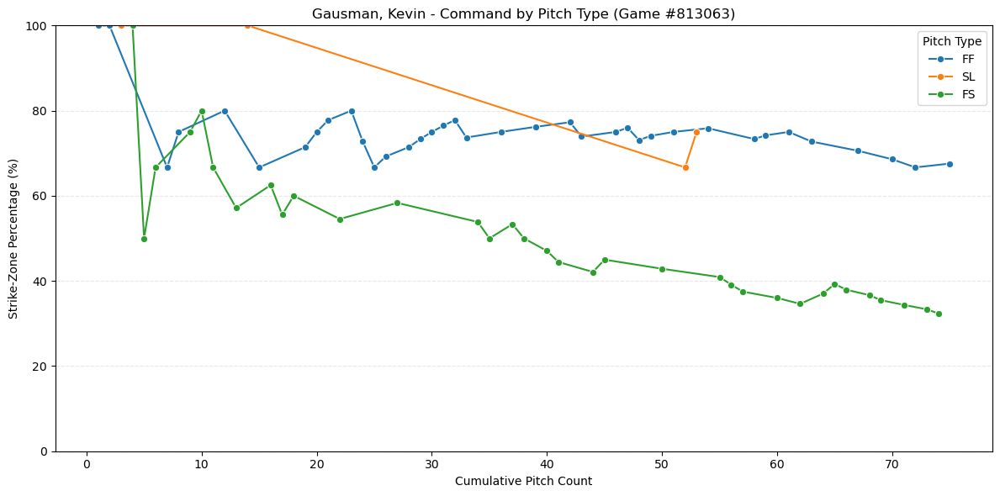

In [15]:
# Copy starting pitcher data
command_data = starter_pitches.copy()

# Convert zone to numeric
command_data["zone"] = pd.to_numeric(
    command_data["zone"], errors="coerce"
)

# Identify pitches in the strike zone
command_data["in_zone"] = command_data["zone"].between(1, 9)

# Calculate cumulative strike-zone percentage for each pitch type
command_data["in_zone_count"] = (
    command_data.groupby(
        ["game_pk", "pitcher", "pitch_type"]
    )["in_zone"].cumsum()
)

command_data["pitch_type_count"] = (
    command_data.groupby(
        ["game_pk", "pitcher", "pitch_type"]
    ).cumcount() + 1
)

command_data["strike_zone_pct"] = (
    command_data["in_zone_count"] /
    command_data["pitch_type_count"] * 100
)

for i in range(len(starters)):

    starter = starters.iloc[i]

    pitcher_data = command_data[
        (command_data["game_pk"] == starter["game_pk"]) &
        (command_data["pitcher"] == starter["pitcher"])
    ].copy()

    plt.figure(figsize=(12, 6))

    sns.lineplot(
        data=pitcher_data,
        x="pitch_count",
        y="strike_zone_pct",
        hue="pitch_type",
        marker="o"
    )

    plt.xlabel("Cumulative Pitch Count")
    plt.ylabel("Strike-Zone Percentage (%)")

    plt.title(
        f"{starter['player_name']} - Command by Pitch Type "
        f"(Game #{starter['game_pk']})"
    )

    plt.ylim(0, 100)
    plt.legend(title="Pitch Type")
    plt.grid(axis="y", linestyle="--", alpha=0.3)
    plt.tight_layout()
    plt.show()

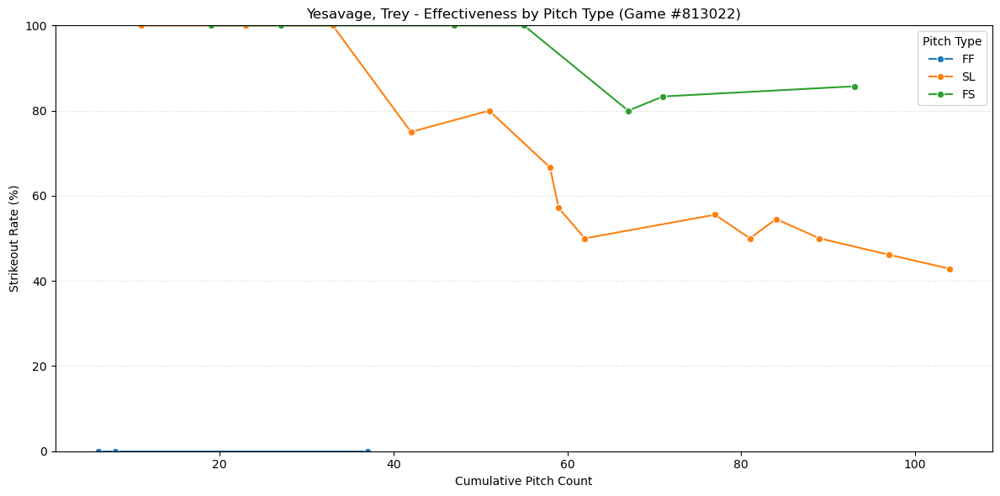

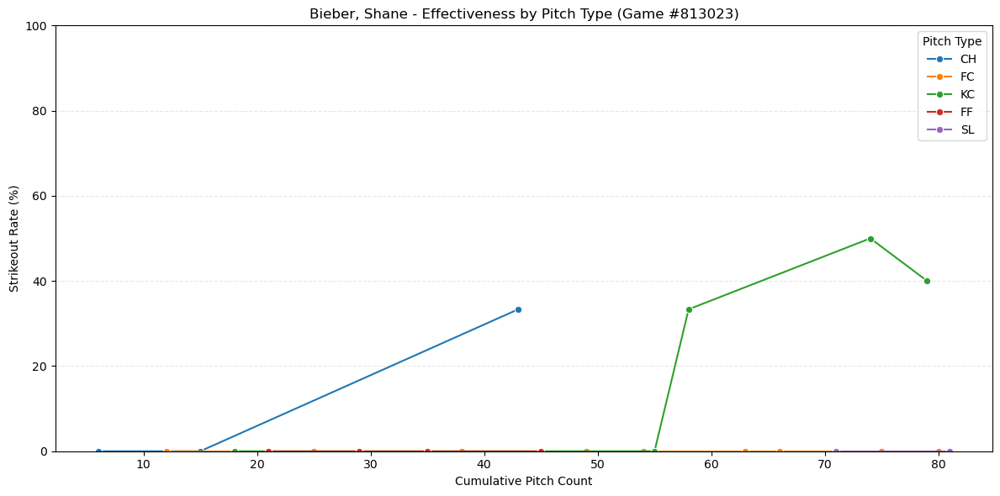

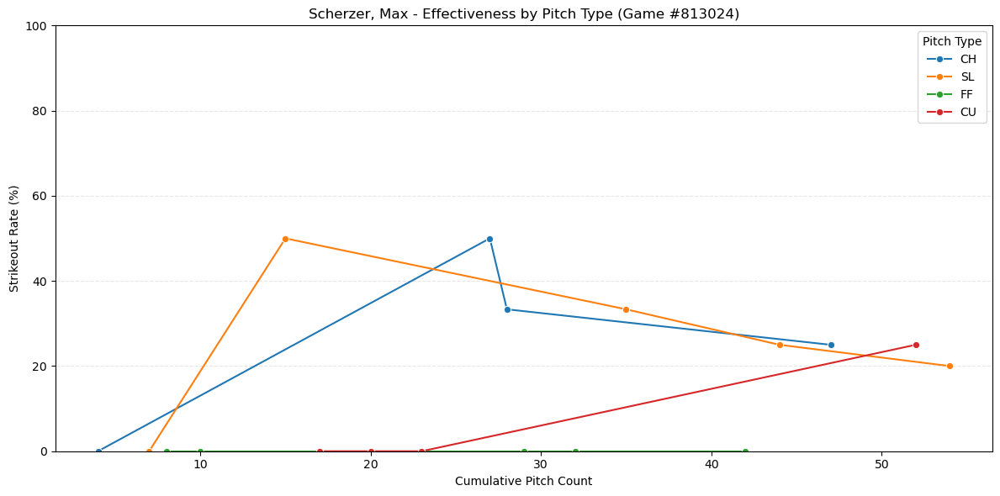

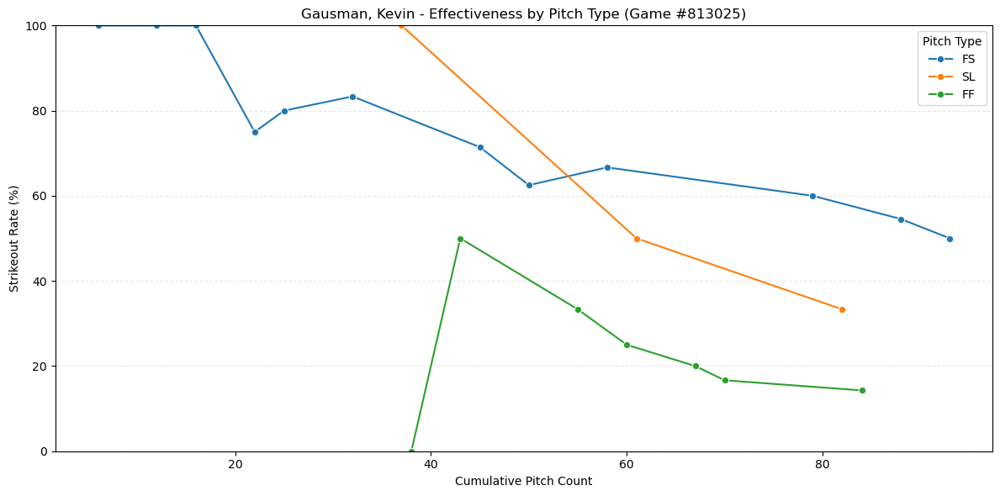

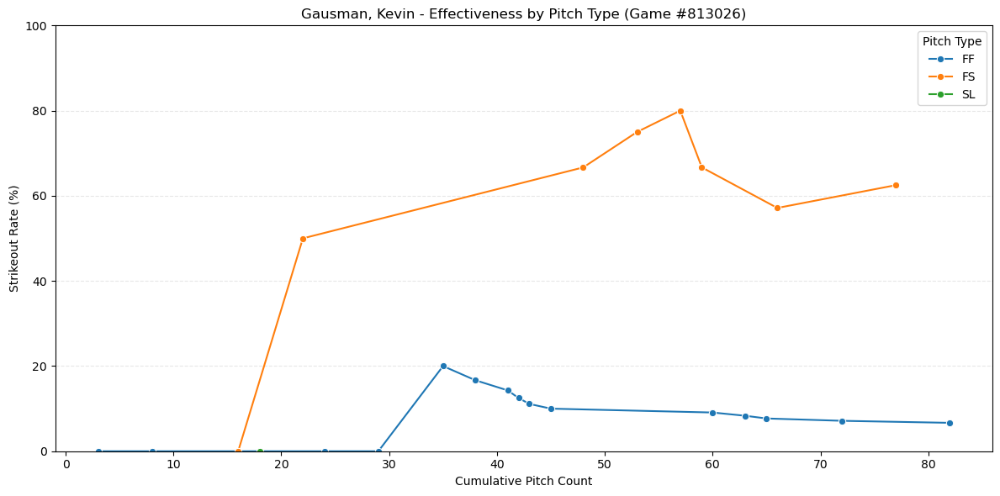

...

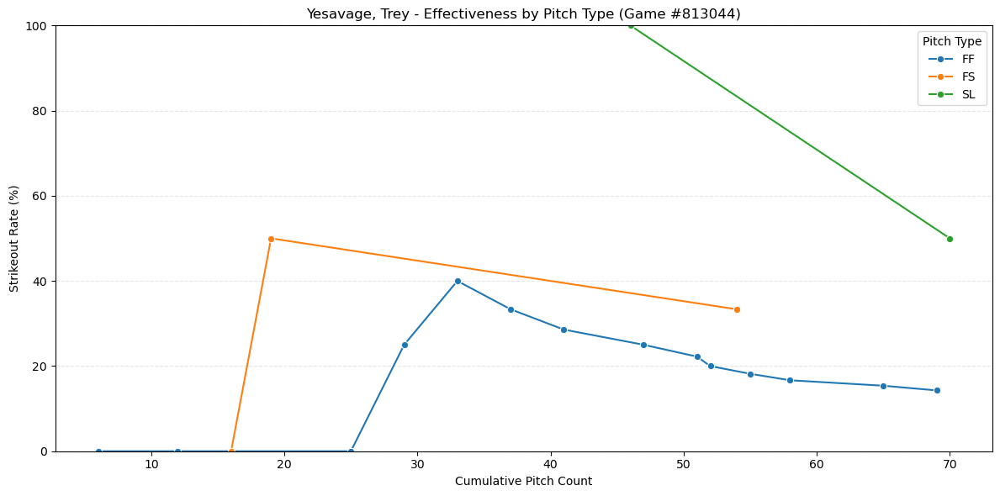

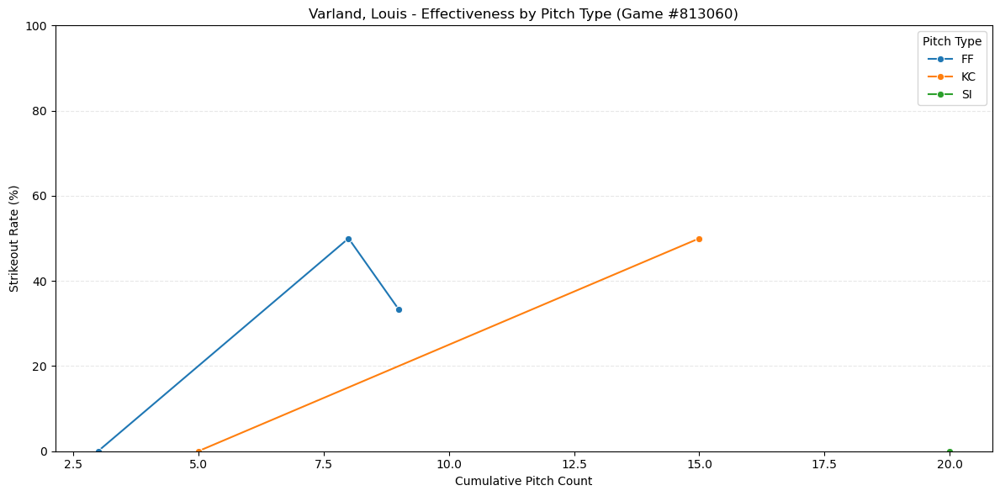

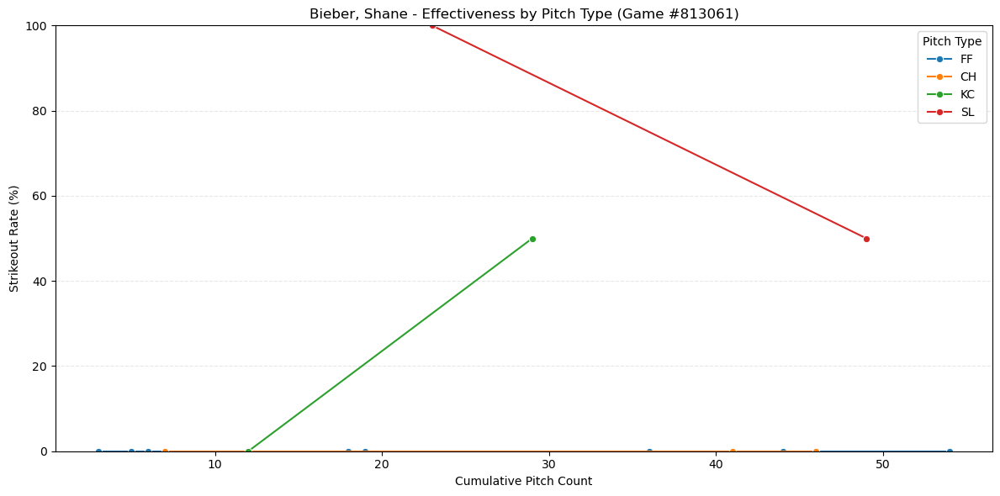

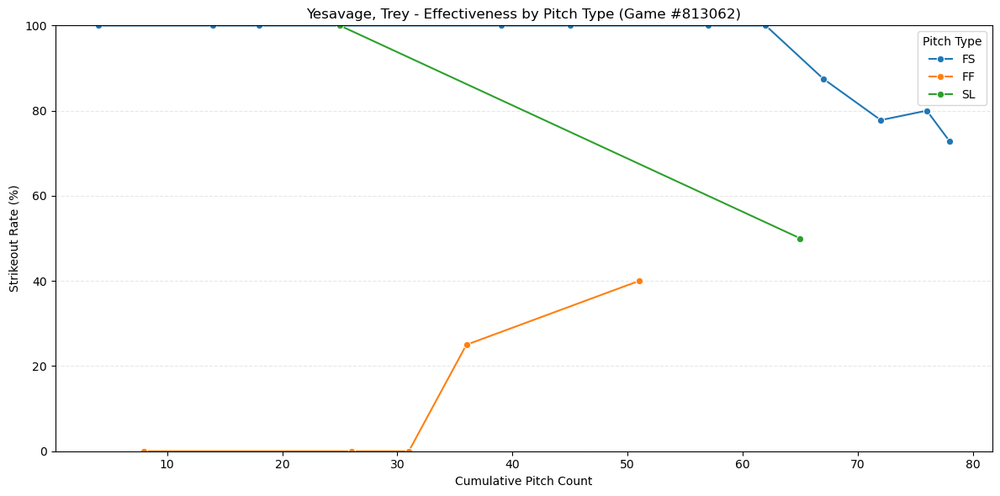

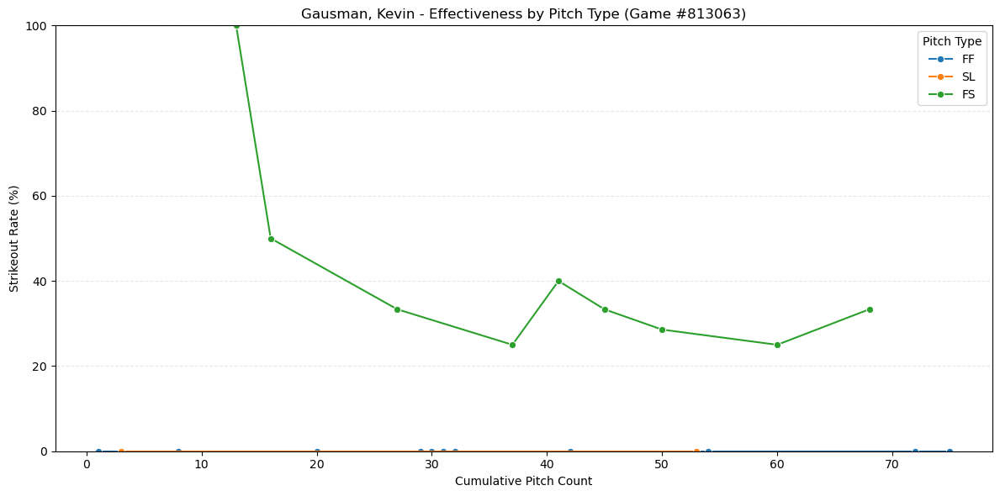

In [16]:
# Copy starting pitcher data
effectiveness_data = starter_pitches.copy()

# Identify completed plate appearances
effectiveness_data["completed_pa"] = (
    effectiveness_data["events"].notna()
)

# Identify strikeouts
effectiveness_data["strikeout"] = effectiveness_data["events"].isin([
    "strikeout",
    "strikeout_double_play"
])

# Keep only completed plate appearances
completed_pa = effectiveness_data[
    effectiveness_data["completed_pa"]
].copy()

# Calculate cumulative strikeouts and completed plate appearances
completed_pa["strikeout_count"] = (
    completed_pa.groupby(
        ["game_pk", "pitcher", "pitch_type"]
    )["strikeout"].cumsum()
)

completed_pa["pa_count"] = (
    completed_pa.groupby(
        ["game_pk", "pitcher", "pitch_type"]
    ).cumcount() + 1
)

# Calculate strikeout rate
completed_pa["strikeout_rate"] = (
    completed_pa["strikeout_count"] /
    completed_pa["pa_count"] * 100
)
for i in range(len(starters)):

    starter = starters.iloc[i]

    pitcher_data = completed_pa[
        (completed_pa["game_pk"] == starter["game_pk"]) &
        (completed_pa["pitcher"] == starter["pitcher"])
    ].copy()

    if pitcher_data.empty:
        continue

    plt.figure(figsize=(12, 6))

    sns.lineplot(
        data=pitcher_data,
        x="pitch_count",
        y="strikeout_rate",
        hue="pitch_type",
        marker="o"
    )

    plt.xlabel("Cumulative Pitch Count")
    plt.ylabel("Strikeout Rate (%)")

    plt.title(
        f"{starter['player_name']} - Effectiveness by Pitch Type "
        f"(Game #{starter['game_pk']})"
    )

    plt.ylim(0, 100)
    plt.legend(title="Pitch Type")
    plt.grid(axis="y", linestyle="--", alpha=0.3)
    plt.tight_layout()
    plt.show()

In [17]:
#add all pitchers and avg each velocity for intervals in all games, eg. 0-15 pitches

 pitcher           player_name pitch_interval pitch_type  average_velocity  total_pitches  games
  453286         Scherzer, Max           1-15         CH             87.05              2      2
  453286         Scherzer, Max           1-15         CU             78.51              7      3
  453286         Scherzer, Max           1-15         FC             90.28              6      3
  453286         Scherzer, Max           1-15         FF             95.43             19      3
  453286         Scherzer, Max           1-15         SL             87.55             11      3
  453286         Scherzer, Max          16-30         CH             86.51              8      3
  453286         Scherzer, Max          16-30         CU             77.18              5      3
  453286         Scherzer, Max          16-30         FC             89.10              1      1
  453286         Scherzer, Max          16-30         FF             94.67             26      3
  453286         Scherzer, Max

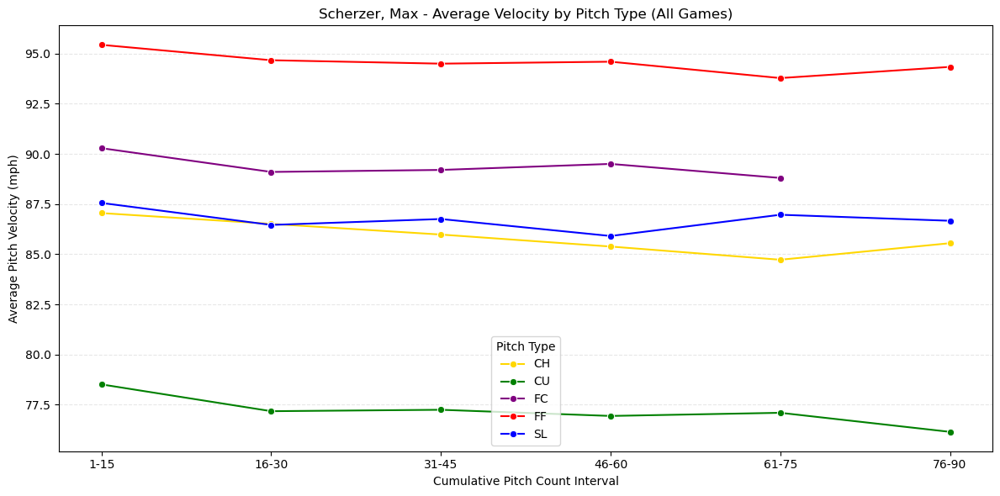

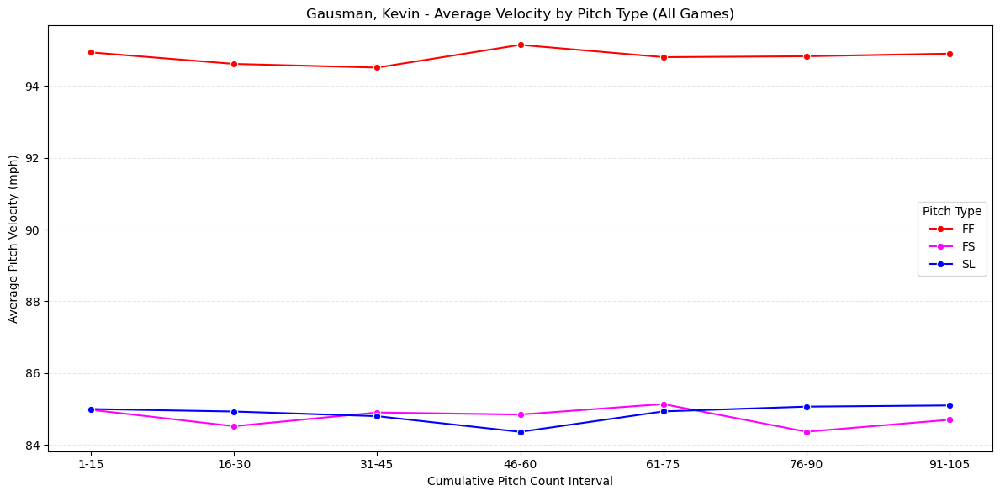

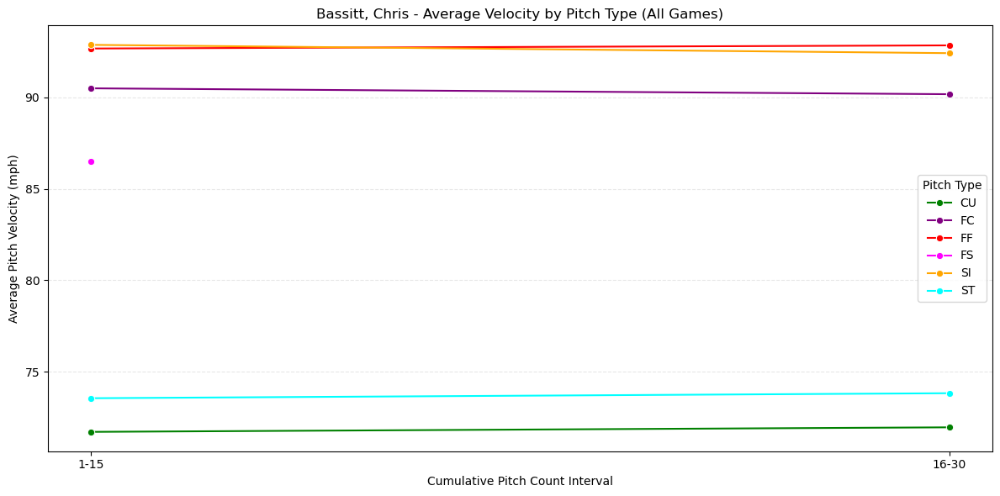

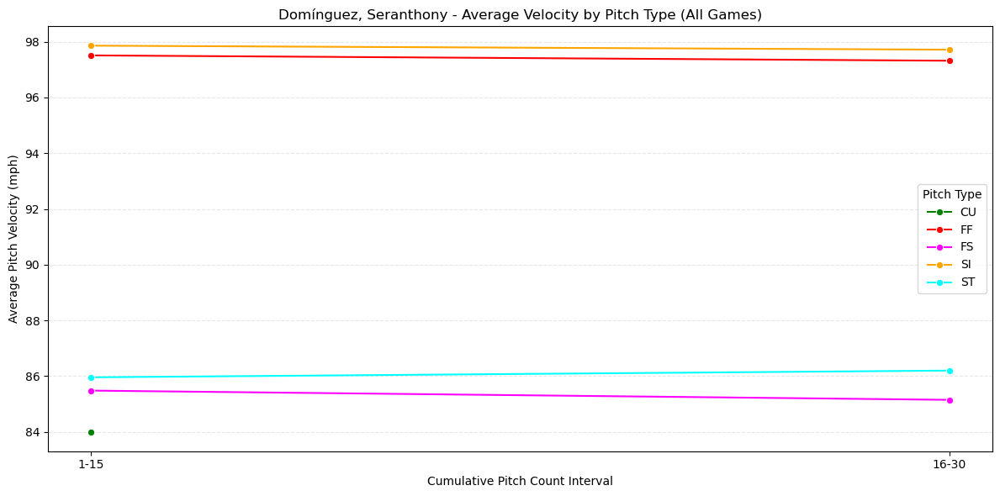

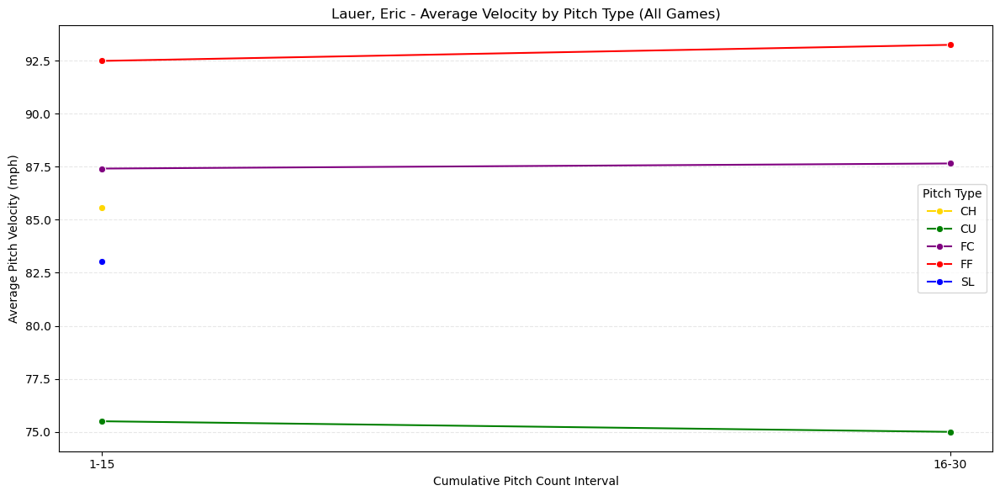

...

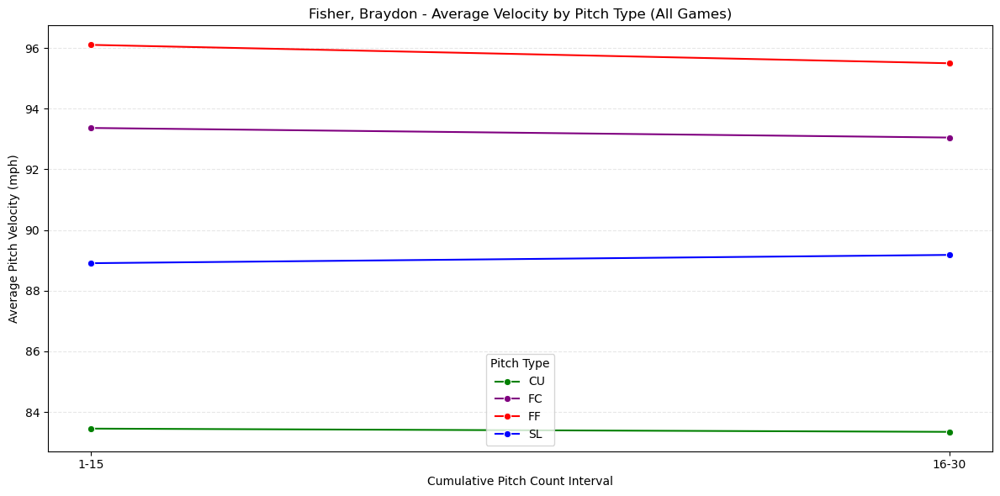

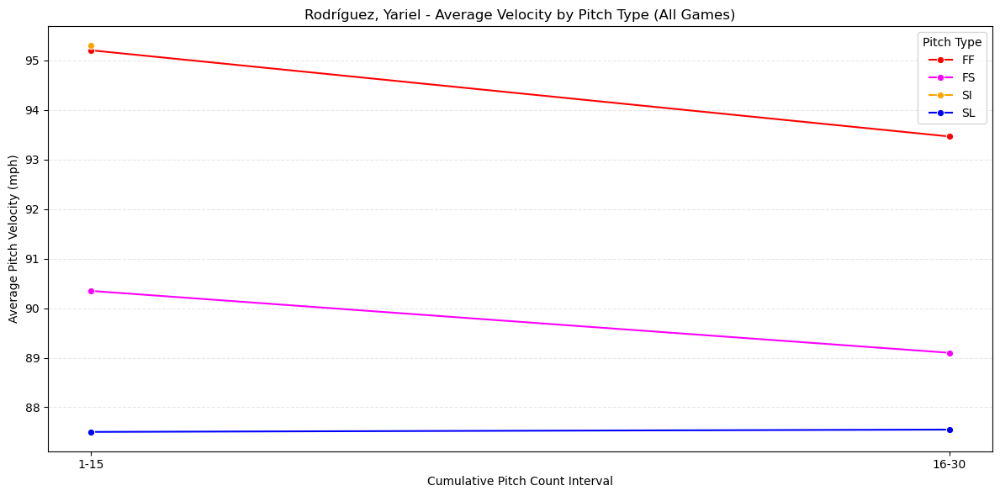

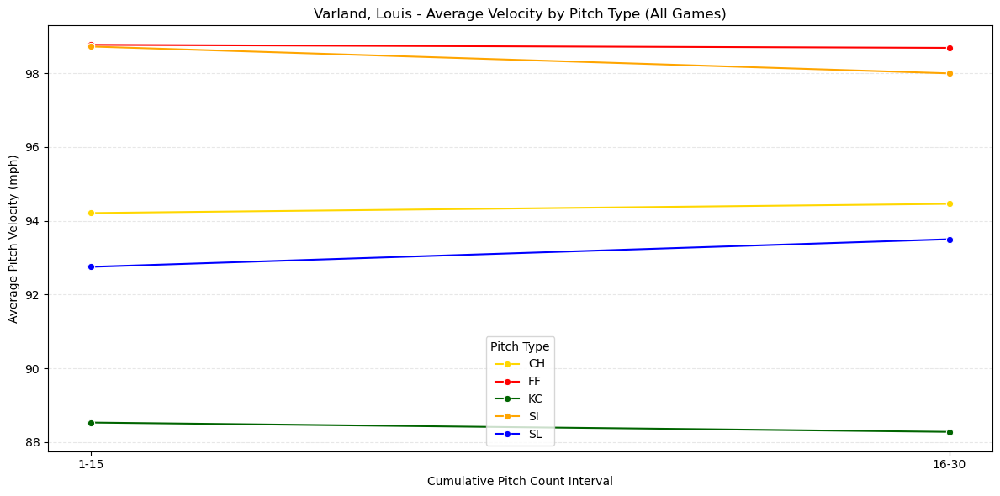

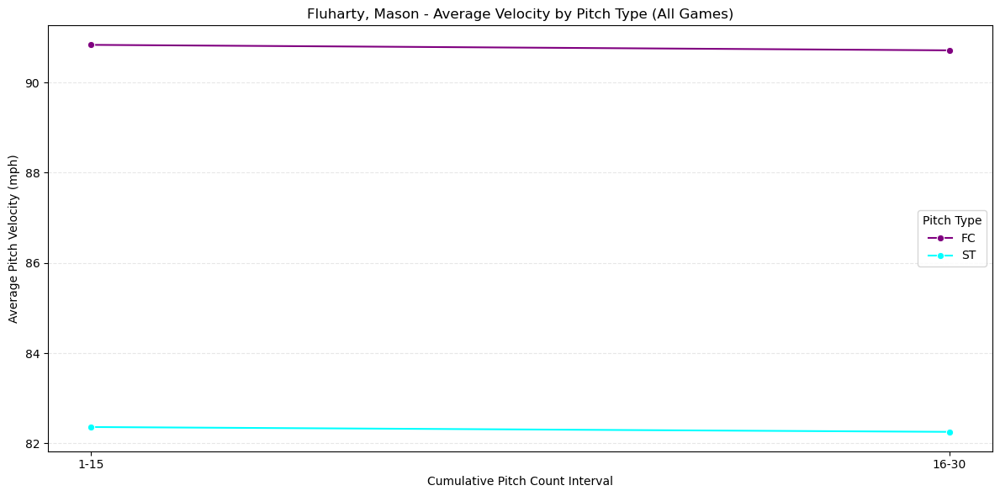

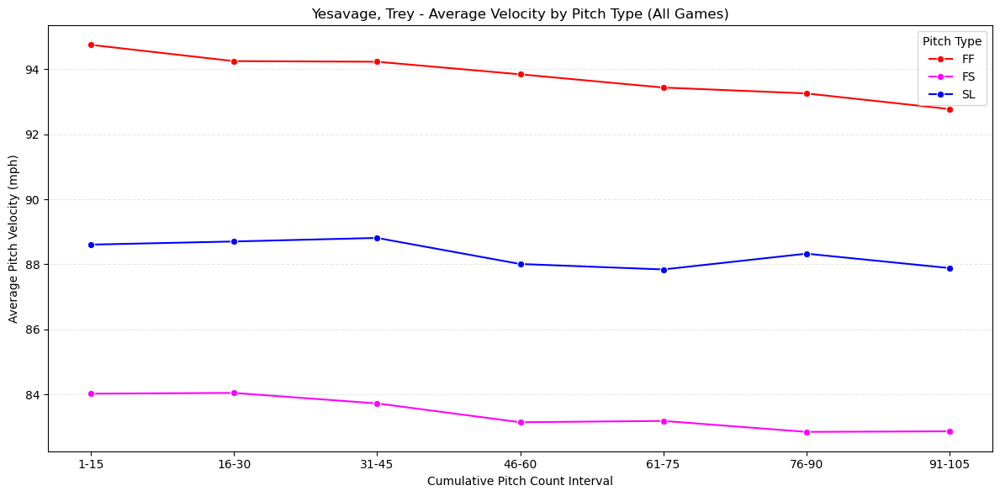

In [18]:
# Keep all Blue Jays pitchers in the first 9 innings
pitch_data = blue_jays[
    blue_jays["inning"].between(1, 9)
].copy()

# Sort pitches chronologically within each game
pitch_data = pitch_data.sort_values(
    ["game_pk", "pitcher", "at_bat_number", "pitch_number"]
)

# Calculate cumulative pitch count for each pitcher in each game
pitch_data["pitch_count"] = (
    pitch_data.groupby(["game_pk", "pitcher"]).cumcount() + 1
)

# Remove pitches without recorded velocity or pitch type
pitch_data = pitch_data.dropna(
    subset=["release_speed", "pitch_type"]
)

# Create pitch-count intervals
pitch_data["pitch_interval"] = pd.cut(
    pitch_data["pitch_count"],
    bins=[0, 15, 30, 45, 60, 75, 90, 105, 120],
    labels=[
        "1-15",
        "16-30",
        "31-45",
        "46-60",
        "61-75",
        "76-90",
        "91-105",
        "106-120"
    ]
)

# Calculate average velocity for each pitcher and pitch type
velocity_intervals = (
    pitch_data.groupby(
        ["pitcher", "player_name", "pitch_interval", "pitch_type"],
        observed=True
    )
    .agg(
        average_velocity=("release_speed", "mean"),
        total_pitches=("release_speed", "count"),
        games=("game_pk", "nunique")
    )
    .reset_index()
)

print(
    velocity_intervals.round(2).to_string(index=False)
)

# Assign consistent colours to pitch types
pitch_colors = {
    "FF": "red",          # 4-Seam Fastball
    "FA": "darkred",      # Fastball
    "SI": "orange",       # Sinker
    "FC": "purple",       # Cutter
    "FT": "brown",        # 2-Seam Fastball
    "SL": "blue",         # Slider
    "ST": "cyan",         # Sweeper
    "CU": "green",        # Curveball
    "KC": "darkgreen",    # Knuckle Curve
    "CH": "gold",         # Changeup
    "FS": "magenta",      # Splitter
    "FO": "pink",         # Forkball
    "SV": "gray",         # Slurve
    "KN": "black",        # Knuckleball
    "EP": "olive"         # Eephus
}

pitchers = velocity_intervals[
    ["pitcher", "player_name"]
].drop_duplicates()

for i in range(len(pitchers)):

    pitcher = pitchers.iloc[i]

    pitcher_data = velocity_intervals[
        velocity_intervals["pitcher"] == pitcher["pitcher"]
    ]

    plt.figure(figsize=(12, 6))

    sns.lineplot(
        data=pitcher_data,
        x="pitch_interval",
        y="average_velocity",
        hue="pitch_type",
        palette=pitch_colors,
        marker="o"
    )

    plt.xlabel("Cumulative Pitch Count Interval")
    plt.ylabel("Average Pitch Velocity (mph)")

    plt.title(
        f"{pitcher['player_name']} - Average Velocity by Pitch Type (All Games)"
    )

    plt.grid(axis="y", linestyle="--", alpha=0.3)
    plt.legend(title="Pitch Type")
    plt.tight_layout()
    plt.show()

 pitcher    player_name  average_difference  games
  453286  Scherzer, Max               -1.68      3
  702056 Yesavage, Trey               -1.60      5
  669456  Bieber, Shane               -1.26      4
  592332 Gausman, Kevin               -0.64      5
  656546  Hoffman, Jeff               -0.43      1


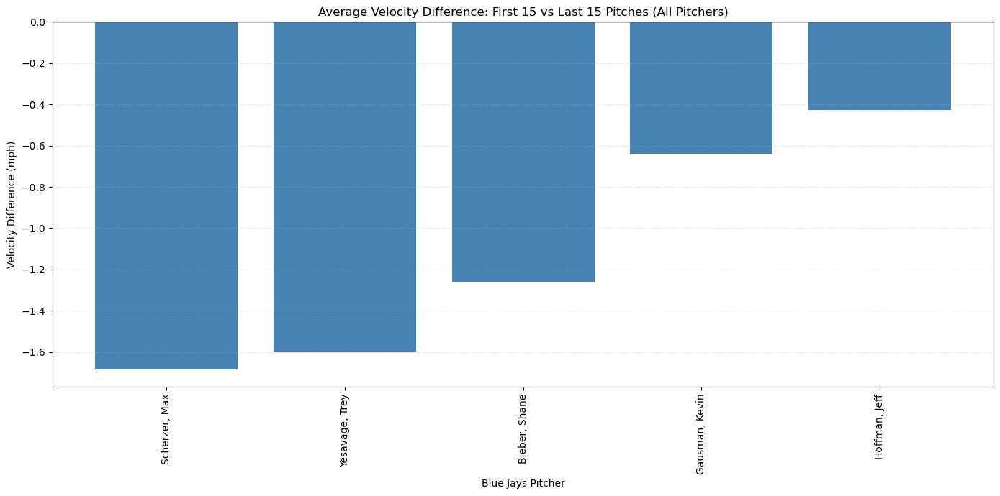

In [19]:
# Start with all Blue Jays pitchers
all_pitchers = blue_jays[
    blue_jays["inning"].between(1, 9)
].copy()

# Sort pitches chronologically
all_pitchers = all_pitchers.sort_values(
    ["game_pk", "pitcher", "at_bat_number", "pitch_number"]
)

# Calculate pitch count for each pitcher in each game
all_pitchers["pitch_count"] = (
    all_pitchers.groupby(["game_pk", "pitcher"]).cumcount() + 1
)

# Find the last pitch count for each outing
all_pitchers["last_pitch_count"] = (
    all_pitchers.groupby(["game_pk", "pitcher"])["pitch_count"]
    .transform("max")
)

# Keep outings with at least 30 pitches
all_pitchers = all_pitchers[
    all_pitchers["last_pitch_count"] >= 30
].copy()

# Identify first and last 15 pitches
all_pitchers["interval"] = np.where(
    all_pitchers["pitch_count"] <= 15,
    "First 15",
    np.where(
        all_pitchers["pitch_count"] > all_pitchers["last_pitch_count"] - 15,
        "Last 15",
        "Other"
    )
)

# Keep first and last 15 pitches
comparison = all_pitchers[
    all_pitchers["interval"].isin(["First 15", "Last 15"])
].dropna(subset=["release_speed"])

# Calculate average velocity for each pitcher in each interval
averages = (
    comparison.groupby(
        ["game_pk", "pitcher", "player_name", "interval"]
    )
    ["release_speed"].mean()
    .unstack()
    .dropna(subset=["First 15", "Last 15"])
    .reset_index()
)

# Calculate velocity difference for each game
averages["difference"] = (
    averages["Last 15"] - averages["First 15"]
)

# Average differences across all games for each pitcher
final_comparison = (
    averages.groupby(["pitcher", "player_name"])
    .agg(
        average_difference=("difference", "mean"),
        games=("game_pk", "nunique")
    )
    .reset_index()
    .sort_values("average_difference")
)

print(final_comparison.round(2).to_string(index=False))

plt.figure(figsize=(14, 7))

plt.bar(
    final_comparison["player_name"],
    final_comparison["average_difference"],
    color="steelblue"
)

plt.axhline(y=0, color="black", linewidth=1)

plt.xlabel("Blue Jays Pitcher")
plt.ylabel("Velocity Difference (mph)")

plt.title(
    "Average Velocity Difference: First 15 vs Last 15 Pitches (All Pitchers)"
)

plt.xticks(rotation=90)
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

 pitcher           player_name  average_difference  games
  605135        Bassitt, Chris               -4.58      6
  669456         Bieber, Shane               -4.00      4
  453286         Scherzer, Max               -3.15      3
  592332        Gausman, Kevin               -1.91      6
  702056        Yesavage, Trey               -1.89      6
  680755       Fisher, Braydon               -1.06      7
  684320     Rodríguez, Yariel               -0.91      3
  656546         Hoffman, Jeff               -0.72      9
  686973        Varland, Louis               -0.68     13
  622554 Domínguez, Seranthony               -0.55      9
  677865        Bruihl, Justin                0.62      1
  663893       Little, Brendon                0.76      4
  641778           Lauer, Eric                0.82      4
  689254       Fluharty, Mason                1.65      7
  667297          Nance, Tommy                3.18      2


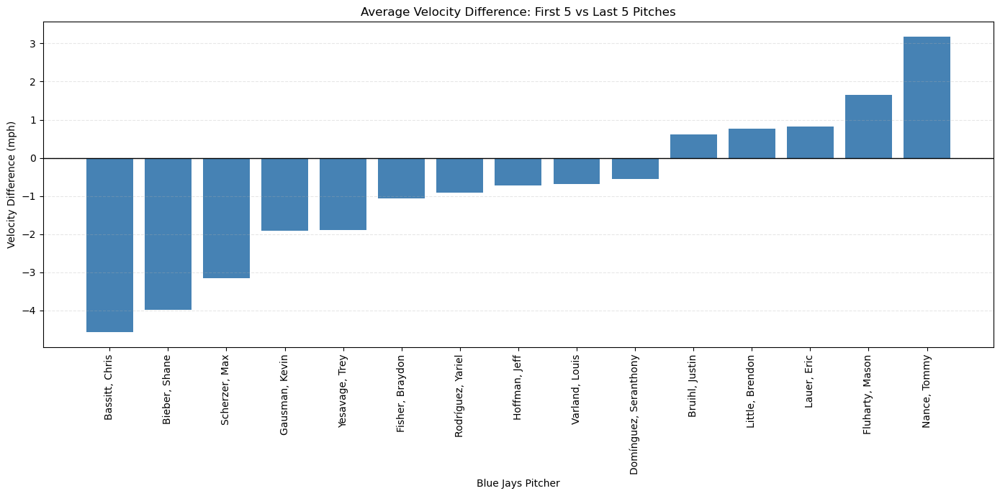

In [20]:
# Start with all Blue Jays pitchers
all_pitchers = blue_jays[
    blue_jays["inning"].between(1, 9)
].copy()

# Sort pitches chronologically
all_pitchers = all_pitchers.sort_values(
    ["game_pk", "pitcher", "at_bat_number", "pitch_number"]
)

# Calculate pitch count for each pitcher in each game
all_pitchers["pitch_count"] = (
    all_pitchers.groupby(["game_pk", "pitcher"]).cumcount() + 1
)

# Find the last pitch count for each outing
all_pitchers["last_pitch_count"] = (
    all_pitchers.groupby(["game_pk", "pitcher"])["pitch_count"]
    .transform("max")
)

# Keep outings with at least 10 pitches
all_pitchers = all_pitchers[
    all_pitchers["last_pitch_count"] >= 10
].copy()

# Identify first 5 and last 5 pitches
all_pitchers["interval"] = np.where(
    all_pitchers["pitch_count"] <= 5,
    "First 5",
    np.where(
        all_pitchers["pitch_count"] > all_pitchers["last_pitch_count"] - 5,
        "Last 5",
        "Other"
    )
)

# Keep first and last 5 pitches
comparison = all_pitchers[
    all_pitchers["interval"].isin(["First 5", "Last 5"])
].dropna(subset=["release_speed"])

# Calculate average velocity for each outing and interval
averages = (
    comparison.groupby(
        ["game_pk", "pitcher", "player_name", "interval"]
    )["release_speed"]
    .mean()
    .unstack()
    .dropna(subset=["First 5", "Last 5"])
    .reset_index()
)

# Calculate difference
averages["difference"] = (
    averages["Last 5"] - averages["First 5"]
)

# Average differences across all games for each pitcher
final_comparison = (
    averages.groupby(["pitcher", "player_name"])
    .agg(
        average_difference=("difference", "mean"),
        games=("game_pk", "nunique")
    )
    .reset_index()
    .sort_values("average_difference")
)

print(final_comparison.round(2).to_string(index=False))

plt.figure(figsize=(14, 7))

plt.bar(
    final_comparison["player_name"],
    final_comparison["average_difference"],
    color="steelblue"
)

plt.axhline(y=0, color="black", linewidth=1)

plt.xlabel("Blue Jays Pitcher")
plt.ylabel("Velocity Difference (mph)")

plt.title(
    "Average Velocity Difference: First 5 vs Last 5 Pitches"
)

plt.xticks(rotation=90)
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

## Hypothesis testing

All tests below use a significance level of α = 0.05.
 
Test 1 - First 15 pitches vs. last 15 pitches
Purpose: Determine whether Blue Jays pitchers average velocity decreases between the first 15 and last 15 pitches of qualifying outings.

Test: One-sample t-test using the differences between paired averages.

Define the difference as:

d={Last 15 average velocity}-{First 15 average velocity}


H_0:mu_d=0 - there is no average change in velocity.



H_a:mu_d<0 - average velocity decreases in the last 15 pitches.

In [22]:
from scipy import stats

# Select Blue Jays pitches from the first 9 innings
all_pitchers = blue_jays[
    blue_jays["inning"].between(1, 9)
].copy()

# Sort pitches chronologically
all_pitchers = all_pitchers.sort_values(
    ["game_pk", "pitcher", "at_bat_number", "pitch_number"]
)

# Calculate pitch count for each pitcher in each game
all_pitchers["pitch_count"] = (
    all_pitchers.groupby(["game_pk", "pitcher"]).cumcount() + 1
)

# Find total pitches per pitcher outing
all_pitchers["last_pitch_count"] = (
    all_pitchers.groupby(["game_pk", "pitcher"])["pitch_count"]
    .transform("max")
)

# Remove pitches without velocity measurements
velocity_data = all_pitchers.dropna(
    subset=["release_speed"]
).copy()

In [23]:
pitcher_velocity = (
    velocity_data.groupby("player_name")
    .agg(
        average_velocity=("release_speed", "mean"),
        median_velocity=("release_speed", "median"),
        standard_deviation=("release_speed", "std"),
        total_pitches=("release_speed", "count")
    )
    .reset_index()
    .sort_values("average_velocity", ascending=False)
)

print(pitcher_velocity.round(2).to_string(index=False))

          player_name  average_velocity  median_velocity  standard_deviation  total_pitches
       Varland, Louis             93.94            94.35                4.64            250
Domínguez, Seranthony             93.34            97.05                5.76            172
      Little, Brendon             92.11            93.60                3.20             67
        Hoffman, Jeff             90.88            89.20                3.90            188
    Rodríguez, Yariel             90.43            88.60                3.65             58
         Nance, Tommy             89.67            89.90                4.08             33
       Gausman, Kevin             89.29            86.25                5.09            436
       Yesavage, Trey             89.15            88.70                4.33            440
        Scherzer, Max             89.03            89.25                6.15            220
      Fisher, Braydon             88.29            88.75                4.47    

In [24]:
pitch_type_velocity = (
    velocity_data.groupby("pitch_type")
    .agg(
        average_velocity=("release_speed", "mean"),
        standard_deviation=("release_speed", "std"),
        total_pitches=("release_speed", "count")
    )
    .reset_index()
    .sort_values("average_velocity", ascending=False)
)

print(pitch_type_velocity.round(2).to_string(index=False))

pitch_type  average_velocity  standard_deviation  total_pitches
        FF             95.10                1.99            881
        SI             94.58                2.35            131
        FC             90.24                2.27            177
        CH             89.88                3.38            122
        SL             87.29                2.06            513
        KC             86.69                2.63            160
        FS             85.04                2.02            393
        ST             82.20                3.74            120
        CU             79.43                4.84            116


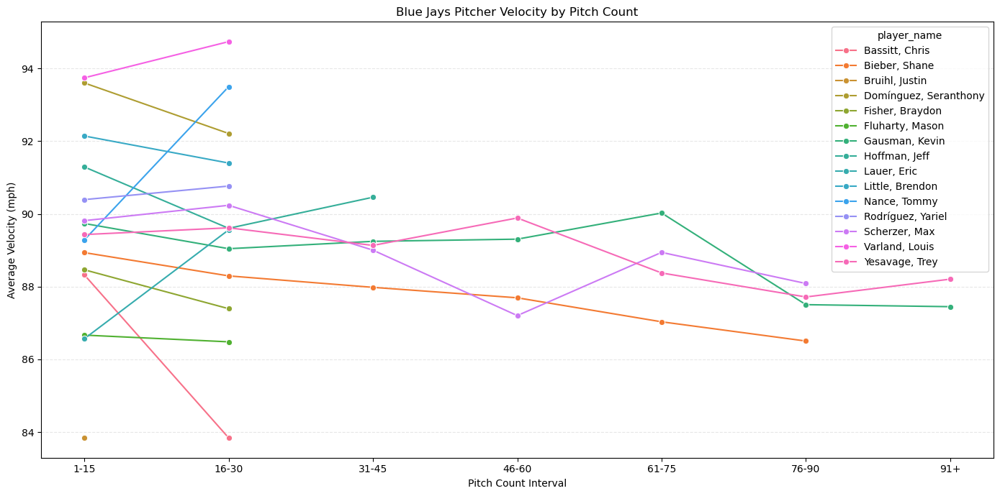

In [25]:
velocity_data["pitch_interval"] = pd.cut(
    velocity_data["pitch_count"],
    bins=[0, 15, 30, 45, 60, 75, 90, float("inf")],
    labels=["1-15", "16-30", "31-45", "46-60",
            "61-75", "76-90", "91+"]
)

interval_velocity = (
    velocity_data.groupby(
        ["player_name", "pitch_interval"],
        observed=True
    )
    .agg(
        average_velocity=("release_speed", "mean"),
        total_pitches=("release_speed", "count")
    )
    .reset_index()
)

plt.figure(figsize=(14, 7))

sns.lineplot(
    data=interval_velocity,
    x="pitch_interval",
    y="average_velocity",
    hue="player_name",
    marker="o"
)

plt.xlabel("Pitch Count Interval")
plt.ylabel("Average Velocity (mph)")
plt.title("Blue Jays Pitcher Velocity by Pitch Count")
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

In [26]:
comparison_data = all_pitchers[
    all_pitchers["last_pitch_count"] >= 30
].copy()

# Identify first and last 15 pitches
comparison_data["interval"] = np.where(
    comparison_data["pitch_count"] <= 15,
    "First 15",
    np.where(
        comparison_data["pitch_count"] > comparison_data["last_pitch_count"] - 15,
        "Last 15",
        "Other"
    )
)

# Keep first and last 15 pitches with available velocity
comparison = comparison_data[
    comparison_data["interval"].isin(["First 15", "Last 15"])
].dropna(subset=["release_speed"])

# Calculate average velocity for each outing
averages = (
    comparison.groupby(
        ["game_pk", "pitcher", "player_name", "interval"]
    )["release_speed"]
    .mean()
    .unstack("interval")
    .dropna(subset=["First 15", "Last 15"])
    .reset_index()
)

# Calculate difference
averages["difference"] = (
    averages["Last 15"] - averages["First 15"]
)

print(averages.round(2).to_string(index=False))

 game_pk  pitcher    player_name  First 15  Last 15  difference
  813022   702056 Yesavage, Trey     89.56    88.45       -1.11
  813023   669456  Bieber, Shane     88.29    87.27       -1.02
  813024   453286  Scherzer, Max     88.74    86.95       -1.79
  813025   592332 Gausman, Kevin     88.03    88.23        0.20
  813026   592332 Gausman, Kevin     90.85    91.21        0.37
  813027   702056 Yesavage, Trey     91.11    89.13       -1.99
  813032   453286  Scherzer, Max     90.63    89.78       -0.85
  813035   453286  Scherzer, Max     90.08    87.66       -2.42
  813037   669456  Bieber, Shane     88.64    86.93       -1.71
  813038   656546  Hoffman, Jeff     90.66    90.23       -0.43
  813038   702056 Yesavage, Trey     88.42    88.84        0.42
  813039   592332 Gausman, Kevin     88.89    85.79       -3.10
  813040   592332 Gausman, Kevin     92.15    90.72       -1.43
  813043   669456  Bieber, Shane     88.66    87.19       -1.47
  813044   702056 Yesavage, Trey     90.

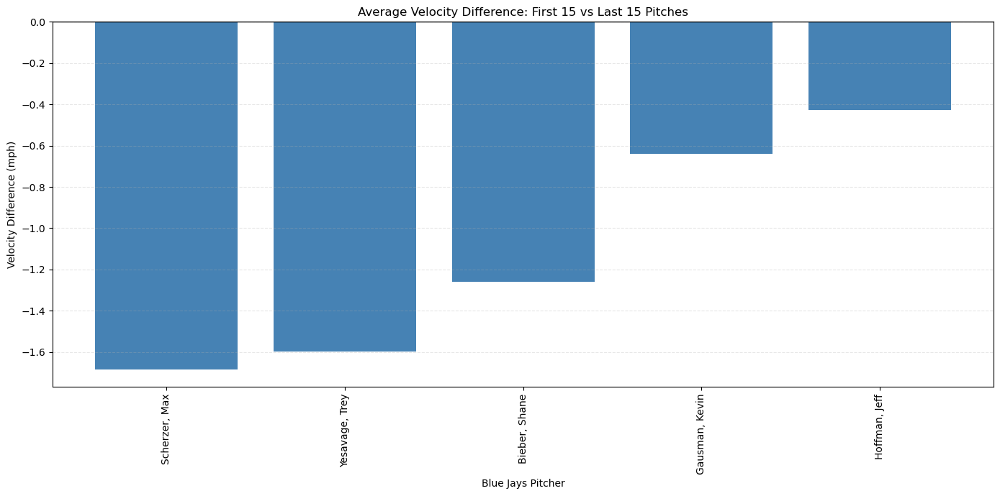

In [27]:
final_comparison = (
    averages.groupby(["pitcher", "player_name"])
    .agg(
        average_difference=("difference", "mean"),
        games=("game_pk", "nunique")
    )
    .reset_index()
    .sort_values("average_difference")
)

plt.figure(figsize=(14, 7))

plt.bar(
    final_comparison["player_name"],
    final_comparison["average_difference"],
    color="steelblue"
)

plt.axhline(y=0, color="black", linewidth=1)

plt.xlabel("Blue Jays Pitcher")
plt.ylabel("Velocity Difference (mph)")
plt.title("Average Velocity Difference: First 15 vs Last 15 Pitches")

plt.xticks(rotation=90)
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

In [29]:
if len(averages) >= 2:

    t_stat, p_value = stats.ttest_rel(
        averages["Last 15"],
        averages["First 15"],
        alternative="less"
    )

    print("Paired outings:", len(averages))
    print("T-statistic:", round(t_stat, 4))
    print("P-value:", round(p_value, 4))

    if p_value < 0.05:
        print("There is statistically significant evidence of a velocity decrease.")
    else:
        print("There is insufficient statistical evidence of a velocity decrease.")

else:
    print("Not enough paired outings to perform a paired t-test.")

Paired outings: 18
T-statistic: -4.3241
P-value: 0.0002
There is statistically significant evidence of a velocity decrease.


Conclusion


Since the p-value is less than 0.05, we reject the null hypothesis. There is statistically significant evidence that Blue Jays pitchers average velocity decreases between their first 15 and last 15 pitches in qualifying outings.

Test 2 - Comparing average velocity among pitchers

Purpose: Determine whether average pitching velocity differs between Blue Jays pitchers.

Test: One-way ANOVA

Hypotheses

H_0:mu_1=mu_2=mu_3=... - all pitchers have the same mean velocity.

H_a: at least one pitcher has a different mean velocity.

In [30]:
pitcher_velocity = (
    velocity_data.groupby("player_name")
    .agg(
        average_velocity=("release_speed", "mean"),
        pitch_count=("release_speed", "count"),
        standard_deviation=("release_speed", "std")
    )
    .reset_index()
    .sort_values("average_velocity", ascending=False)
)

print(pitcher_velocity.round(2).to_string(index=False))

          player_name  average_velocity  pitch_count  standard_deviation
       Varland, Louis             93.94          250                4.64
Domínguez, Seranthony             93.34          172                5.76
      Little, Brendon             92.11           67                3.20
        Hoffman, Jeff             90.88          188                3.90
    Rodríguez, Yariel             90.43           58                3.65
         Nance, Tommy             89.67           33                4.08
       Gausman, Kevin             89.29          436                5.09
       Yesavage, Trey             89.15          440                4.33
        Scherzer, Max             89.03          220                6.15
      Fisher, Braydon             88.29          112                4.47
        Bieber, Shane             87.95          297                3.57
       Bassitt, Chris             87.19          122                8.85
          Lauer, Eric             86.92           6

In [31]:
import statsmodels.api as sm
from statsmodels.formula.api import ols

mod = ols(
    "release_speed ~ player_name",
    data=velocity_data
).fit()

aov_table = sm.stats.anova_lm(mod, typ=2)

print(aov_table)

                   sum_sq      df          F        PR(>F)
player_name  11881.296959    14.0  34.112342  6.157067e-85
Residual     64634.355976  2598.0        NaN           NaN


Since the p-value is less than the significance level of 0.05, 
the null hypothesis is rejected.

There is statistically significant evidence that average pitching 
velocity differs among Blue Jays pitchers during the 2025 postseason.

The ANOVA test indicates that at least one pitcher has a 
different average velocity from the others. However, this test 
does not identify which specific pitchers have significantly 
different velocities.

Test 3 — Comparing average velocity among pitch types (ANOVA)

Purpose: Determine whether average pitching velocity differs between pitch types (such as four-seam fastballs, sliders, and curveballs).

Hypotheses

H_0:mu_{FF}=\mu_{SL}=mu_{CU}=... - all pitch types have the same mean velocity.

H_a: at least one pitch type has a different mean velocity.



In [32]:
pitch_type_velocity = (
    velocity_data.groupby("pitch_type")
    .agg(
        average_velocity=("release_speed", "mean"),
        pitch_count=("release_speed", "count"),
        standard_deviation=("release_speed", "std")
    )
    .reset_index()
    .sort_values("average_velocity", ascending=False)
)

print(pitch_type_velocity.round(2).to_string(index=False))

pitch_type  average_velocity  pitch_count  standard_deviation
        FF             95.10          881                1.99
        SI             94.58          131                2.35
        FC             90.24          177                2.27
        CH             89.88          122                3.38
        SL             87.29          513                2.06
        KC             86.69          160                2.63
        FS             85.04          393                2.02
        ST             82.20          120                3.74
        CU             79.43          116                4.84


In [33]:
mod_pitch_type = ols(
    "release_speed ~ pitch_type",
    data=velocity_data
).fit()

aov_pitch_type = sm.stats.anova_lm(
    mod_pitch_type,
    typ=2
)

print(aov_pitch_type)

                  sum_sq      df            F  PR(>F)
pitch_type  60812.759944     8.0  1260.567296     0.0
Residual    15702.892991  2604.0          NaN     NaN


The ANOVA test produced an F-statistic of 1260.567 
and a p-value approximately equal to 0.

Since the p-value is less than the significance level 
of 0.05, the null hypothesis is rejected.

There is statistically significant evidence that average 
pitching velocity differs across pitch types.

The ANOVA test indicates that at least one pitch type 
has a different average velocity from the others. However, 
the test does not identify which specific pitch types 
have significantly different average velocities.